# 00 — Present Last-FM (`lastfm-u25` và `lastfm-u25-latest`) với cô Châu (14/11/2026, 13:00)

**Bản rút gọn** của `00_present_lastfm.ipynb` (bản đầy đủ giữ nguyên, dùng khi cô hỏi sâu). Tài liệu học đi kèm: `docs/study/11-tong-hop-ly-thuyet-lastfm.md`,
`12-hoc-va-bao-cao-lastfm.md`, `13-huong-dan-present-lastfm.md`.

**Mạch trình bày (~24 phút):** `lastfm-u25` (phần 1–5) → ba vấn đề của `lastfm-u25` (6.1) → bản mới `lastfm-u25-latest` của Phôn (6.2–6.6) → kế hoạch và ba câu hỏi xin ý kiến cô (7).

| # | Phần | Người trình bày | Phút |
|---|---|---|---|
| 1 | Vì sao Last-FM; protocol không đổi; ba câu hỏi nghiên cứu | Triết | 1,5 |
| 2 | Dữ liệu `lastfm-u25`: nguồn, chia, thời gian, KG, hạn chế của tập cặp | Triết | 4 |
| 3 | Huấn luyện: quy trình, siêu tham số, learning curve | Triết | 2,5 |
| 4 | Kết quả và nhận xét trên `lastfm-u25` | Triết | 3 |
| 5 | Minh bạch và hạn chế của `lastfm-u25` | Triết | 1,5 |
| 6.0–6.1 | Nguồn số liệu; ba vấn đề A, B, C của `lastfm-u25` | Triết | 3,5 |
| 6.2–6.6 | `lastfm-u25-latest`: so sánh, Stage 1, Stage 2, kết quả, hạn chế | Phôn | 5 |
| 7 | Kế hoạch và các câu hỏi xin ý kiến cô | Cả hai | 3 |

**Quy tắc của notebook**
- **Không huấn luyện lại.** Chỉ đọc kết quả đã lưu và vẽ hình từ `docs/figures/` hoặc từ dữ liệu đã xử lý.
- **Không gõ số bằng tay.** Phần 1–5: số trong lời dẫn được in ra từ code, từ `results/registry.csv`, `results/rq3_models.csv`, `results/rq3_pairs.csv`,
  `results/significance.csv`, `docs/data-report-lastfm-numbers.md`, hoặc tính từ `data/processed/lastfm-u25/`. Phần 6: từ `docs/data-report-lastfm-latest-numbers.md`,
  `results/rq3_models_lastfm-latest.csv`, `results/rq3_pairs_lastfm-latest.csv`, `results/lastfm-latest-provenance.json`, hoặc tính từ `data/processed/lastfm-u25-latest/`.
- **Phần 1–5 chỉ `lastfm-u25`; phần 6 chỉ `lastfm-u25-latest`**, đặt cạnh `lastfm-u25`. Mọi bảng ghi rõ tên run.
- **`lastfm-u25-latest` chưa nằm trong `results/registry.csv`** và quyết định 0015 (bản nháp của Phôn) chưa vào repo; số của nó đến từ các bảng tóm tắt (6.0). Kết quả là **sơ bộ**.
- **Đã bỏ khỏi bản rút gọn** (có trong bản đầy đủ): trích nguyên văn quyết định 0012 (Context, Pair selection), bằng chứng không rò rỉ của `lastfm-u25`, tính toán và Kaggle,
  learning curve và bảng điểm lưới, epoch, thời gian chạy của `lastfm-u25-latest`.
- **Điều kiện chạy:** cần `data/processed/lastfm-u25/` và `data/processed/lastfm-u25-latest/`; thiếu thì các ô đọc dữ liệu báo "chưa có".


In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

from tkgat import registry
from tkgat.analysis import eda
from tkgat.analysis.report import parse_numbers, vn_p, vn_pm
from tkgat.data.leakage import check_split
from tkgat.pipeline.build import load_saved

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DS = "lastfm-u25"
NUMS = parse_numbers((ROOT / "docs/data-report-lastfm-numbers.md").read_text(encoding="utf-8"))
ML = parse_numbers((ROOT / "docs/data-report-numbers.md").read_text(encoding="utf-8"))
REG_ALL = registry.load(ROOT / "results/registry.csv")  # newest run per dataset/split/model/config/seed/phase
REG = REG_ALL[REG_ALL["dataset"] == DS]
HAVE_DATA = (ROOT / "data/processed" / DS / "meta.json").exists()
NOT_RUN = "chưa chạy"


def V(key):
    # a number or text of docs/data-report-lastfm-numbers.md, exactly as the script wrote it (Vietnamese format)
    if key not in NUMS:
        raise KeyError(f"{key!r} is not in docs/data-report-lastfm-numbers.md")
    return NUMS[key][0]


def M(key):
    # same, for the MovieLens report docs/data-report-numbers.md
    if key not in ML:
        raise KeyError(f"{key!r} is not in docs/data-report-numbers.md")
    return ML[key][0]


def say(text):
    display(Markdown(text))


def show(df):
    # table without the row index; falls back to a plain table when the Styler (jinja2) is missing
    try:
        display(df.style.hide(axis="index"))
    except Exception:
        display(df)


def figure(name, width=760):
    path = ROOT / "docs/figures" / name
    if path.exists():
        display(Image(filename=path, width=width))
    else:
        say(f"*chưa có: `docs/figures/{name}`.*")


def read_text(rel):
    return (ROOT / rel).read_text(encoding="utf-8")


def num(value, digits=4):
    return f"{value:.{digits}f}".replace(".", ",")


def pct(value, digits=1):
    return f"{100 * value:.{digits}f}".replace(".", ",") + "%"


say(
    f"> Số liệu đọc từ `docs/data-report-lastfm-numbers.md` ({len(NUMS)} khóa) và `results/registry.csv`: "
    f"**{len(REG)}** dòng mới nhất mỗi khóa của `{DS}`, commit {', '.join(sorted(REG['git_commit'].unique()))}, "
    f"**{int(REG['git_commit'].str.contains('dirty').sum())}** dòng `-dirty`. "
    f"Freebase là **bản chụp ngày {V('conv.freebase_snapshot')}**, không phải tri thức có sẵn năm 2014: "
    "mọi kết quả dùng KG phải nêu điều này. **Kết quả KGAT và T-KGAT là sơ bộ** (chưa có tag `v0.2-kgat`)."
)
if not HAVE_DATA:
    say('**Chưa có `data/processed/lastfm-u25/`:** các ô đọc dữ liệu đã xử lý sẽ báo "chưa có".')

> Số liệu đọc từ `docs/data-report-lastfm-numbers.md` (284 khóa) và `results/registry.csv`: **139** dòng mới nhất mỗi khóa của `lastfm-u25`, commit ce55c0c, **0** dòng `-dirty`. Freebase là **bản chụp ngày 09/08/2015**, không phải tri thức có sẵn năm 2014: mọi kết quả dùng KG phải nêu điều này. **Kết quả KGAT và T-KGAT là sơ bộ** (chưa có tag `v0.2-kgat`).

## 1. Vì sao Last-FM; protocol không đổi; ba câu hỏi nghiên cứu
*Người trình bày: Triết*

Theo hướng cô gợi ý (ngày 01/11): chuyển sang Last-FM và lặp lại các thí nghiệm của MovieLens. **Protocol không đổi**: cùng mã chia,
cùng phân vị của t1/t2, k-core chỉ trên train, cùng `check_split`, cùng luật KG, cùng lưới, cùng 5 seed. Chỉ dataset khác.
Dưới đây là phần Context của quyết định 0012, nguyên văn (bao gồm việc quyết định được đưa ra sau khi đã xem test MovieLens):

In [2]:
decision_0012 = read_text("docs/decisions/0012-lastfm-dataset.md")
ctx = re.search(r"- Context:(.*?)\n- Decision:", decision_0012, re.S)
say(
    "*(nguyên văn từ file quyết định, tiếng Anh)*\n\n> " + " ".join(ctx.group(1).split())
    if ctx
    else "*chưa có: không tìm thấy mục Context trong 0012.*"
)

rows = []
for path in sorted((ROOT / "docs/decisions").glob("001[234]-*.md")):
    lines = path.read_text(encoding="utf-8").splitlines()
    status = next((x for x in lines if x.startswith("- Status:")), "- Status: ?")
    rows.append(
        {
            "quyết định": path.stem,
            "tiêu đề": lines[0].lstrip("# ").strip(),
            "Status (nguyên văn)": status.removeprefix("- Status:").strip(),
        }
    )
pd.set_option("display.max_colwidth", None)
show(pd.DataFrame(rows))

*(nguyên văn từ file quyết định, tiếng Anh)*

> On 2026-11-01 the advisor said the MovieLens results point to a problem in the input data and asked the group to switch to Last-FM and repeat the MovieLens experiments. The KGAT release of Last-FM has no timestamps and no validation split. Timestamps come from LFM-1b (`lfm1b-tracks.inter`, cached as `kgat_author_earliest.tsv`). The decision to move to Last-FM was taken after the MovieLens test scores were seen (0009, 0010, 0011); it follows the advisor's direction and was not chosen to improve a score.

quyết định,tiêu đề,Status (nguyên văn)
0012-lastfm-dataset,0012 — Last-FM as a second dataset,"accepted (2026-11-06, Triết); proposed 2026-11-05 (Triết). The dataset builder is Phôn's PR #41 (""lastfm: building script for tkgat"")."
0013-lastfm-u25,0013 — Last-FM: official run on a user subset (lastfm-u25),"accepted (2026-11-06, Triết); proposed 2026-11-05 (Triết; subset changed from `lastfm-u10` to `lastfm-u25` on 2026-11-06). Follows 0008"
0014-lastfm-stage2-kaggle,0014 — Last-FM: Stage 2 runs on Kaggle,"accepted (2026-11-09, Triết); proposed 2026-11-08 (Triết). Follows 0013 (official Last-FM run on `lastfm-u25`; its"


**Ba câu hỏi nghiên cứu** (đọc từ `docs/plan.md`):

In [3]:
rq = [
    cell.strip()
    for line in read_text("docs/plan.md").splitlines()
    if line.startswith("| RQ")
    for cell in [line.split("|")[1]]
]
say("\n".join(f"- {x}" for x in rq) if rq else "*chưa có: không tìm thấy dòng RQ trong `docs/plan.md`.*")
say(
    "*Câu RQ1 trong `docs/plan.md` viết cho MovieLens. Với Last-FM, phần 2 của notebook là phần tương ứng (đặc điểm "
    "thời gian của dữ liệu và KG). "
    "RQ2 và RQ3 được lặp lại nguyên văn ở phần 4.*"
)

- RQ1. Dữ liệu MovieLens và KG liên kết có đặc điểm gì theo thời gian: độ phủ liên kết, tỷ lệ fact có ngày, tỷ lệ fact "tương lai" so với rating?
- RQ2. Khi đã loại rò rỉ (có val, KG theo mốc), KG và metadata còn giúp KGAT hơn lọc cộng tác thuần hay không?
- RQ3. Đưa thời gian vào attention (giảm theo Δt trên cạnh user–item như thiết kế 07/08, so sánh với thời gian trên các triple của KG) có cải thiện thêm không, và cải thiện có thật sự đến từ tín hiệu thời gian không?

*Câu RQ1 trong `docs/plan.md` viết cho MovieLens. Với Last-FM, phần 2 của notebook là phần tương ứng (đặc điểm thời gian của dữ liệu và KG). RQ2 và RQ3 được lặp lại nguyên văn ở phần 4.*

## 2. Dữ liệu Last-FM: nguồn, chia theo thời gian, KG
*Người trình bày: Triết*

**Ba nguồn ghép lại** (quyết định 0012): (1) tập cặp (user, item) và KG mà tác giả KGAT công bố, không có timestamp; (2) **LFM-1b**,
nguồn timestamp, mỗi cặp giữ **lần nghe sớm nhất**; (3) **bản chụp Freebase** cho ngày của fact, qua ngày tồn tại của đích.
Last-FM không có rating: mọi cặp là tương tác dương (`min_rating` = 1). Không cần liên kết thực thể như MovieLens vì dùng
đúng tập user/item của tác giả.

**Chia theo mốc t1/t2** (phân vị 0,8 và 0,9 của mọi timestamp; 5-core chỉ trên train; val/test chỉ giữ user và item đã có trong train).
Cột `lastfm-u25` là tập của các lần chạy chính thức (25% user, quyết định 0013); cột `lastfm` là bộ đầy đủ, chỉ để đối chiếu (không chạy được trên máy hiện có); ML-100K để so với MovieLens:

In [4]:
def col(prefix):
    return {
        "cặp (user, item)": V(f"{prefix}.pairs"),
        "t1 / t2": f"{V(f'{prefix}.t1')} / {V(f'{prefix}.t2')}",
        "positive train": V(f"{prefix}.train_pos"),
        "user / item train": f"{V(f'{prefix}.users')} / {V(f'{prefix}.items')}",
        "positive val (user)": f"{V(f'{prefix}.val_pos')} ({V(f'{prefix}.val_users')})",
        "positive test (user)": f"{V(f'{prefix}.test_pos')} ({V(f'{prefix}.test_users')})",
        "val giữ lại": V(f"{prefix}.val_kept_share"),
        "test giữ lại": V(f"{prefix}.test_kept_share"),
        "val mất vì cold user / cold item": f"{V(f'{prefix}.val_dropped_cold_user_share')} / "
        f"{V(f'{prefix}.val_dropped_cold_item_share')}",
        "test mất vì cold user / cold item": f"{V(f'{prefix}.test_dropped_cold_user_share')} / "
        f"{V(f'{prefix}.test_dropped_cold_item_share')}",
        "positive bị 5-core loại khỏi train": V(f"{prefix}.kcore_removed"),
    }


table = pd.DataFrame(
    {
        "lastfm-u25 (chính thức)": col("lastfm-u25"),
        "lastfm (đầy đủ, đối chiếu)": col("lastfm"),
    }
)
display(table)
say(
    f"**ML-100K để so sánh:** giữ lại {V('cmp.ml100k.val_kept_share')} positive val và "
    f"{V('cmp.ml100k.test_kept_share')} test, "
    f"còn {V('cmp.ml100k.val_users')} và {V('cmp.ml100k.test_users')} user; ML-1M: {V('cmp.ml1m.test_kept_share')} "
    f"test, {V('cmp.ml1m.test_users')} user. "
    f"`{DS}` có {V('lastfm-u25.val_users')} user val và {V('lastfm-u25.test_users')} user test, nên kiểm định có sức "
    "mạnh thật."
)
say(
    f"**Cái giá của 25% user:** {V('lastfm-u25.val_dropped_cold_item_share')} positive val và "
    f"{V('lastfm-u25.test_dropped_cold_item_share')} positive test "
    f"bị loại vì **cold item** (bộ đầy đủ: {V('lastfm.val_dropped_cold_item_share')} và "
    f"{V('lastfm.test_dropped_cold_item_share')}). "
    f"Kết quả chỉ nói cho mẫu {V('lastfm-u25.user_fraction')} user ({V('lastfm-u25.users_sampled')}, seed "
    f"{V('lastfm-u25.user_seed')}), không nói cho toàn Last-FM."
)

,lastfm-u25 (chính thức),"lastfm (đầy đủ, đối chiếu)"
"cặp (user, item)",370.979,1.542.856
t1 / t2,29/04/2014 / 07/06/2014,28/04/2014 / 06/06/2014
positive train,236.053,1.220.988
user / item train,5.321 / 18.665,22.040 / 44.788
positive val (user),23.708 (2.319),142.023 (10.618)
positive test (user),22.419 (1.608),133.896 (7.149)
val giữ lại,"63,9%","92,1%"
test giữ lại,"60,4%","86,8%"
val mất vì cold user / cold item,"7,3% / 28,8%","5,0% / 3,0%"
test mất vì cold user / cold item,"11,5% / 28,1%","8,6% / 4,6%"


**ML-100K để so sánh:** giữ lại 12,6% positive val và 13,3% test, còn 66 và 51 user; ML-1M: 75,7% test, 952 user. `lastfm-u25` có 2.319 user val và 1.608 user test, nên kiểm định có sức mạnh thật.

**Cái giá của 25% user:** 28,8% positive val và 28,1% positive test bị loại vì **cold item** (bộ đầy đủ: 3,0% và 4,6%). Kết quả chỉ nói cho mẫu 25% user (5.892 / 23.566, seed 2019), không nói cho toàn Last-FM.

**Độ cũ Δt của cạnh train trên Last-FM** (điều kiện để Stage 1 có tác dụng). Ba số đầu đọc từ `docs/data-report-lastfm-numbers.md`
(`scripts/07_report_numbers_lastfm.py` tính chúng từ `train.csv` bằng `eda.node_time_spread`, cùng hàm tạo các số của MovieLens, mốc t1)
và so với số của báo cáo dữ liệu MovieLens; các số Δt_norm bên dưới vẫn tính trực tiếp từ `train.csv`:

In [5]:
if HAVE_DATA:
    meta = json.loads(read_text(f"data/processed/{DS}/meta.json"))
    tr = pd.read_csv(ROOT / f"data/processed/{DS}/train.csv")
    t1 = int(meta["t1"])
    rows = [
        {
            "bộ dữ liệu": "Last-FM u25 (báo cáo dữ liệu Last-FM)",
            "user có mọi cạnh train trong < 1 giờ": V(f"{DS}.spread.user_under_1h"),
            "trung vị độ lệch chuẩn thời gian theo user": f"{V(f'{DS}.spread.user_std_days_median')} ngày",
            "trung vị độ lệch chuẩn thời gian theo item": f"{V(f'{DS}.spread.item_std_days_median')} ngày",
        },
        {
            "bộ dữ liệu": "ML-100K (báo cáo dữ liệu)",
            "user có mọi cạnh train trong < 1 giờ": M("ml100k.user_spread_under_1h"),
            "trung vị độ lệch chuẩn thời gian theo user": f"{M('ml100k.user_std_minutes_median')} phút",
            "trung vị độ lệch chuẩn thời gian theo item": f"{M('ml100k.item_std_days_median')} ngày",
        },
        {
            "bộ dữ liệu": "ML-1M (báo cáo dữ liệu)",
            "user có mọi cạnh train trong < 1 giờ": M("ml1m.user_spread_under_1h"),
            "trung vị độ lệch chuẩn thời gian theo user": f"{M('ml1m.user_std_minutes_median')} phút",
            "trung vị độ lệch chuẩn thời gian theo item": f"{M('ml1m.item_std_days_median')} ngày",
        },
    ]
    display(pd.DataFrame(rows).set_index("bộ dữ liệu"))

    t_ref, t_min = int(tr["ts"].max()), int(tr["ts"].min())
    x = (t_ref - tr["ts"]) / (t_ref - t_min)  # Δt_norm of Stage 1 (T_ref = max train ts)
    q = x.quantile([0.25, 0.5, 0.75, 0.9])
    say(
        f"- **Δt_norm của {len(tr):,}".replace(",", ".") + f" cạnh train**: trung vị {num(q[0.5], 3)}; tứ phân vị "
        f"{num(q[0.25])} và {num(q[0.75])}; phân vị 90 là {num(q[0.9])}. "
        f"{pct(((t_ref - tr['ts']) <= 30 * 86400).mean())} cạnh nằm trong 30 ngày cuối, "
        f"{pct(((t_ref - tr['ts']) <= 365 * 86400).mean())} trong 365 ngày cuối. "
        f"Cửa sổ train {num((t_ref - t_min) / 86400 / 365.25, 2)} năm (báo cáo dữ liệu: "
        f"{V('lastfm-u25.dt.window_years')} năm)."
    )
    say(
        "**Đọc:** khác MovieLens (rating nhập theo phiên nên Δt theo user gần bằng 0), thời gian của Last-FM trải "
        "rộng ở cả phía user và phía item. "
        'Stage 1 được đo trong điều kiện thuận lợi hơn, nên kết quả "không có tác dụng" ở phần 4 không thể giải '
        'thích bằng "Δt không có thông tin".'
    )
else:
    say("*chưa có: cần `data/processed/lastfm-u25/` (script 02).*")

,user có mọi cạnh train trong < 1 giờ,trung vị độ lệch chuẩn thời gian theo user,trung vị độ lệch chuẩn thời gian theo item
bộ dữ liệu,,,
Last-FM u25 (báo cáo dữ liệu Last-FM),"0,53%","249,6 ngày","552,6 ngày"
ML-100K (báo cáo dữ liệu),"53,0%",14 phút,45 ngày
ML-1M (báo cáo dữ liệu),"53,4%",14 phút,67 ngày


- **Δt_norm của 236.053 cạnh train**: trung vị 0,100; tứ phân vị 0,0147 và 0,2229; phân vị 90 là 0,4316. 22,0% cạnh nằm trong 30 ngày cuối, 52,1% trong 365 ngày cuối. Cửa sổ train 9,20 năm (báo cáo dữ liệu: 9,20 năm).

**Đọc:** khác MovieLens (rating nhập theo phiên nên Δt theo user gần bằng 0), thời gian của Last-FM trải rộng ở cả phía user và phía item. Stage 1 được đo trong điều kiện thuận lợi hơn, nên kết quả "không có tác dụng" ở phần 4 không thể giải thích bằng "Δt không có thông tin".

**Dấu vết của hạn chế quan trọng nhất của dữ liệu: số cạnh train theo tuần.** Tập cặp của bản Last-FM mà KGAT công bố chỉ chứa các cặp còn được
nghe từ 01/04/2014. Nếu đúng, số cặp mới mỗi tuần phải nhảy lên quanh mốc đó (đường đỏ):

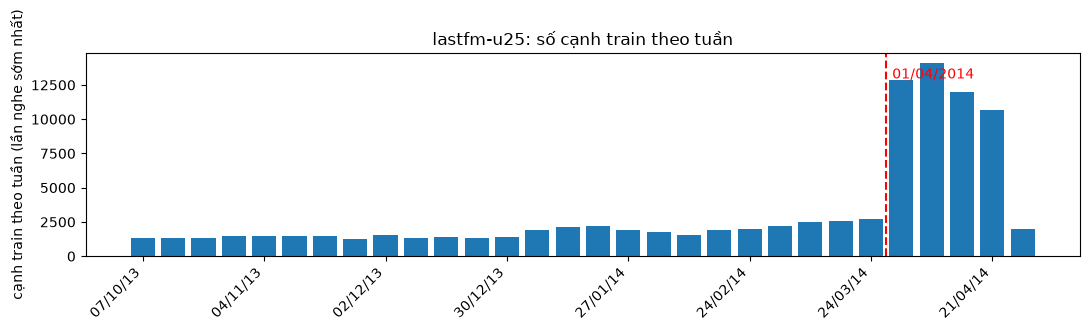

Trung bình 2.494 cạnh mỗi tuần trong 4 tuần trước 31/03/2014 và 12.416 trong 4 tuần từ 31/03/2014 (`docs/data-report-lastfm-numbers.md`, tính từ `train.csv` bằng `eda.weekly_counts`).

In [6]:
if HAVE_DATA:
    weekly = eda.weekly_counts(tr)
    weekly = weekly[weekly.index >= "2013-10-01"]
    fig, ax = plt.subplots(figsize=(11, 3.2))
    ax.bar(range(len(weekly)), weekly.values, width=0.8)
    ax.set_xticks(range(0, len(weekly), 4))
    ax.set_xticklabels([d.strftime("%d/%m/%y") for d in weekly.index[::4]], rotation=45, ha="right")
    ax.set_ylabel("cạnh train theo tuần (lần nghe sớm nhất)")
    marker = pd.Timestamp("2014-03-31")  # Monday of the week that contains 2014-04-01
    if marker in weekly.index:
        pos = list(weekly.index).index(marker)
        ax.axvline(pos - 0.5, color="red", ls="--")
        ax.text(pos - 0.3, weekly.max() * 0.92, "01/04/2014", color="red")
    ax.set_title(f"{DS}: số cạnh train theo tuần")
    plt.tight_layout()
    plt.show()
    say(
        f"Trung bình {V(f'{DS}.week.before_mean')} cạnh mỗi tuần trong 4 tuần trước 31/03/2014 và "
        f"{V(f'{DS}.week.after_mean')} trong 4 tuần từ 31/03/2014 "
        "(`docs/data-report-lastfm-numbers.md`, tính từ `train.csv` bằng `eda.weekly_counts`)."
    )

**KG theo thời gian.** Quy tắc như MovieLens (quyết định 0004 và 0006): KG tại mốc *t* chỉ giữ fact đã đúng trước *t*; KG cho train/val dựng tại t1,
cho test dựng tại t2. KG Last-FM không có ngày của statement: ngày của fact là ngày tồn tại của đích (sớm nhất của `release_date`,
`active_start`, `date_of_birth`).

In [8]:
k = "lastfm-u25.kg."
say(
    f"""
- **Từ KG gốc tới KG của pipeline:** {V(k + "author_triples")} triple → {V(k + "item_seeded")} (lọc theo item) →
  {V(k + "head_seeded")} (chở được trong định dạng 1-hop; bỏ {V(k + "dropped_not_1hop")} =
  {V(k + "dropped_not_1hop_share")}, head không phải item của train).
  {V(k + "entities")} thực thể ({V(k + "tail_entities")} thực thể đích), {V(k + "relations")} quan hệ.
- **Fact không có ngày:** {V(k + "undated_t1")} triple ({V(k + "undated_t1_share")});
  {V(k + "relations_fully_undated")} quan hệ hoàn toàn không có ngày.
- **Bộ lọc thời gian gần như không cắt gì:** chỉ {V(k + "filtered_t1")} triple ({V(k + "filtered_t1_share")}) bị lọc
  tại t1 (MovieLens: {M("ml100k.filtered_share_t1")} ở ML-100K, {M("ml1m.filtered_share_t1")} ở ML-1M).
  KG tại t1 và t2 giống hệt nhau ({V(k + "default.t1")} và {V(k + "default.t2")} triple); số thực thể chỉ có ở t2:
  {V(k + "entities_only_in_t2")}.
  **Last-FM không đo được hiện tượng "fact tương lai rơi giữa hai mốc"** (ví dụ *Titanic*); câu hỏi rò rỉ qua KG vẫn
  trả lời bằng MovieLens.
"""
)
variants = pd.DataFrame(
    {
        "KG tại t1": [
            V(k + "default.t1"),
            V(k + "drop_undated.t1"),
            V(k + "static.t1"),
        ],
        "KG tại t2": [
            V(k + "default.t2"),
            V(k + "drop_undated.t2"),
            V(k + "static.t2"),
        ],
    },
    index=["default", "drop_undated", "static (tham chiếu)"],
)
display(variants)
rel = sorted(
    ((key.removeprefix(k + "no_date."), NUMS[key][0]) for key in NUMS if key.startswith(k + "no_date.")),
    key=lambda kv: -float(kv[1].rstrip("%").replace(",", ".")),
)
say("**Tỷ lệ fact không có ngày theo quan hệ** (`lastfm-u25`):")
display(pd.DataFrame(rel, columns=["quan hệ", "không có ngày"]).set_index("quan hệ"))


- **Từ KG gốc tới KG của pipeline:** 464.567 triple → 154.076 (lọc theo item) →
  152.979 (chở được trong định dạng 1-hop; bỏ 1.097 =
  0,7%, head không phải item của train).
  44.392 thực thể (25.727 thực thể đích), 9 quan hệ.
- **Fact không có ngày:** 30.323 triple (19,8%);
  4 quan hệ hoàn toàn không có ngày.
- **Bộ lọc thời gian gần như không cắt gì:** chỉ 3 triple (0,0%) bị lọc
  tại t1 (MovieLens: 1,3% ở ML-100K, 1,5% ở ML-1M).
  KG tại t1 và t2 giống hệt nhau (152.976 và 152.976 triple); số thực thể chỉ có ở t2:
  0.
  **Last-FM không đo được hiện tượng "fact tương lai rơi giữa hai mốc"** (ví dụ *Titanic*); câu hỏi rò rỉ qua KG vẫn
  trả lời bằng MovieLens.


,KG tại t1,KG tại t2
default,152.976,152.976
drop_undated,122.653,122.653
static (tham chiếu),152.979,152.979


**Tỷ lệ fact không có ngày theo quan hệ** (`lastfm-u25`):

,không có ngày
quan hệ,
common.topic.notable_types,"100,0%"
music.single.versions,"100,0%"
music.recording.canonical_version,"100,0%"
music.recording.song,"100,0%"
music.recording.engineer,"74,8%"
music.recording.producer,"27,5%"
music.recording.featured_artists,"5,1%"
music.recording.releases,"1,9%"
music.recording.artist,"1,1%"


**Thang Δt của Stage 2** (quyết định 0009: `dt_norm` của cạnh KG bị chặn ở 1). Đây là điểm Last-FM khác MovieLens rõ nhất. Lưu ý: `dt_norm` chia cho **cửa sổ của tương tác train** (quyết định 0009, mục 3), không phải cửa sổ của fact, nên fact cũ hơn cửa sổ đều bị chặn ở 1:

In [9]:
rows = [
    {
        "bộ dữ liệu": label,
        "trong cửa sổ (dt_norm < 1)": V(f"{key}.dt.inside_window_share"),
        "bị chặn ở 1": V(f"{key}.dt.capped_share"),
        "không có ngày": V(f"{key}.dt.undated_share"),
        "cửa sổ train (năm)": V(f"{key}.dt.window_years"),
    }
    for key, label in (
        ("lastfm-u25", "Last-FM u25"),
        ("ml-100k", "ML-100K"),
        ("ml-1m-u10", "ml-1m-u10 (10% user của ML-1M)"),
    )
]
display(pd.DataFrame(rows).set_index("bộ dữ liệu"))
say(
    f"Trên `{DS}` {V('lastfm-u25.dt.inside_window_share')} số triple nằm trong cửa sổ, nên Stage 2 chỉ có độ phân giải "
    "với phần fact đó, chưa phải phép thử đầy đủ về fact cũ hay mới "
    f"(MovieLens: {V('ml-100k.dt.inside_window_share')} và {V('ml-1m-u10.dt.inside_window_share')}). "
    f"Cảnh báo: {V('lastfm-u25.dt.capped_share')} số triple vẫn bị chặn ở 1 (trung vị `dt_norm` của fact có ngày: "
    f"{V('lastfm-u25.dt.median_dated')}), "
    "nên kết luận chỉ áp dụng cho phần fact đủ mới. Ngày của fact là ngày tồn tại của đích, không phải lúc fact vào KG."
)

,trong cửa sổ (dt_norm < 1),bị chặn ở 1,không có ngày,cửa sổ train (năm)
bộ dữ liệu,,,,
Last-FM u25,"24,4%","55,7%","19,8%","9,20"
ML-100K,"0,7%","82,6%","16,7%","0,46"
ml-1m-u10 (10% user của ML-1M),"0,0%","83,3%","16,7%","0,60"


Trên `lastfm-u25` 24,4% số triple nằm trong cửa sổ, nên Stage 2 chỉ có độ phân giải với phần fact đó, chưa phải phép thử đầy đủ về fact cũ hay mới (MovieLens: 0,7% và 0,0%). Cảnh báo: 55,7% số triple vẫn bị chặn ở 1 (trung vị `dt_norm` của fact có ngày: 1,45), nên kết luận chỉ áp dụng cho phần fact đủ mới. Ngày của fact là ngày tồn tại của đích, không phải lúc fact vào KG.

## 3. Huấn luyện mô hình
*Người trình bày: Triết*

**Quy trình chung** (giống MovieLens): mỗi điểm lưới × 5 seed (2019–2023); Recall@20 trên val mỗi 5 epoch; dừng sớm khi val không tăng
(patience 5 với BPR-MF, 10 với KGAT; tối đa 300 epoch); giữ epoch tốt nhất trên val; chọn điểm lưới có trung bình Recall@20 val cao nhất;
**chấm test một lần**; mọi dòng val và test ghi vào `results/registry.csv` (chỉ thêm, có git commit). T-KGAT giữ (lr, l2) của KGAT
và chỉ dò γ ∈ {1, 3, 10}.

**Tham số huấn luyện BPR-MF** (`docs/bprmf-training-table.md`, cột `lastfm-u25`):

,lastfm-u25
Tham số,
Batch size,2048
Số epoch tối đa,300
Đánh giá val mỗi (epoch),5
Patience (số lần đánh giá),5
Chỉ số chọn,recall@20
Learning rate,0.001
L2,0.001
Dim,64
Điểm lưới được chọn trên val,2 / 3


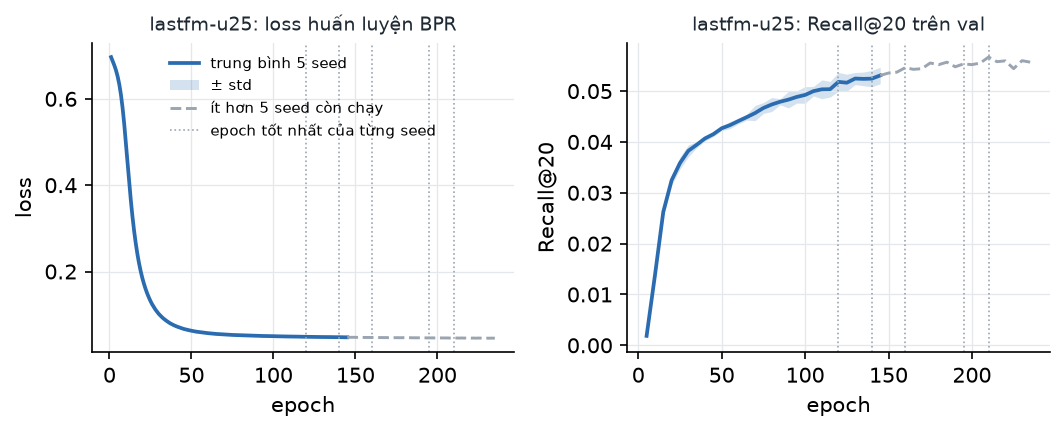

Hình: loss huấn luyện và Recall@20 val của BPR-MF (trung bình ± std qua 5 seed); vạch chấm là epoch tốt nhất của từng seed, **chọn theo val**, test không tham gia.

In [11]:
lines = [ln for ln in read_text("docs/bprmf-training-table.md").splitlines() if ln.startswith("|")]
cells = [[c.strip() for c in ln.strip().strip("|").split("|")] for ln in lines]
display(pd.DataFrame([r[:2] for r in cells[2:]], columns=cells[0][:2]).set_index(cells[0][0]))
figure("fig5_bprmf_curve_lastfm-u25.png")
say(
    "Hình: loss huấn luyện và Recall@20 val của BPR-MF (trung bình ± std qua 5 seed); vạch chấm là epoch tốt nhất "
    "của từng seed, **chọn theo val**, test không tham gia."
)

**Lưới và điểm được chọn** (trung bình Recall@20 **val** qua 5 seed, từ registry; điểm in đậm trong bài nói là điểm có val cao nhất của từng mô hình):

In [12]:
VAL = REG[REG["phase"] == "val"].copy()
DROP = {"dt_den", "t_ref", "perm_seed", "l2_kg", "mess_dropout"}


def short(cfg):
    d = json.loads(cfg)
    return ", ".join(f"{k} = {v}" for k, v in d.items() if k not in DROP)


VAL["điểm lưới"] = VAL["config"].map(short)
g = (
    VAL[VAL["model"].isin(["bprmf", "kgat", "kgat_nokg", "tkgat", "tkgat_kg"])]
    .groupby(["model", "điểm lưới"])
    .agg(val_recall20=("recall@20", "mean"), n_seed=("seed", "nunique"))
)
g["val_recall20"] = g["val_recall20"].map(num)
display(g)


def epoch_range(model, which):
    # the best epochs of one model at its selected grid point, as docs/data-report-lastfm-numbers.md wrote them
    return V(f"{DS}.best_epoch.{model}.chosen.{which}")


def epoch_cap(model):
    # the epoch limit of the model's own config (kgat.yaml for the KGAT family, bprmf.yaml for BPR-MF)
    return int(V("conv.max_epochs_bprmf" if model == "bprmf" else "conv.max_epochs"))


def as_int(text):
    return int(text.replace(".", ""))


train_models = [m for m in sorted(VAL["model"].unique()) if not m.startswith("mostpop")]  # MostPop has no epochs
epochs = pd.DataFrame(
    [
        {
            "mô hình": m,
            "epoch tốt nhất, nhỏ nhất": epoch_range(m, "min"),
            "epoch tốt nhất, lớn nhất": epoch_range(m, "max"),
            "giới hạn epoch": epoch_cap(m),
        }
        for m in train_models
    ]
).set_index("mô hình")
say(
    "**Epoch tốt nhất chọn trên val** của điểm lưới đã chọn (trung bình Recall@20 val cao nhất; "
    f"nhỏ nhất và lớn nhất qua {V('conv.seeds')} seed, từ `docs/data-report-lastfm-numbers.md`, mục 6):"
)
display(epochs)
at_cap = [m for m in train_models if as_int(epoch_range(m, "max")) >= epoch_cap(m)]
if at_cap:
    say(
        "Ở điểm đã chọn, ít nhất một seed của "
        + ", ".join(f"`{m}`" for m in at_cap)
        + " có epoch tốt nhất bằng giới hạn epoch: huấn luyện của seed đó dừng vì hết giới hạn, chưa dừng sớm trên val."
    )
else:
    say("Ở điểm đã chọn, không seed nào của mô hình nào có epoch tốt nhất bằng giới hạn epoch.")
say(
    "Điểm được chọn ở các mô hình nằm ở **mép lưới** (ví dụ BPR-MF l2 lớn nhất, KGAT lr lớn nhất, γ = 10 ở Stage 1 "
    "và γ = 1 ở Stage 2), và chênh lệch val giữa các γ nhỏ "
    "(xem bảng): đây là hạn chế đã biết, chưa mở rộng lưới."
)

val_recall20  \
model     điểm lưới                                                       
bprmf     dim = 32, l2 = 0.0001, lr = 0.001                      0,0391   
          dim = 64, l2 = 0.0001, lr = 0.001                      0,0503   
          dim = 64, l2 = 0.001, lr = 0.001                       0,0559   
kgat      l2 = 0.0001, lr = 0.0001                               0,0433   
          l2 = 0.0001, lr = 0.001                                0,0555   
          l2 = 1e-05, lr = 0.0001                                0,0434   
          l2 = 1e-05, lr = 0.001                                 0,0561   
kgat_nokg l2 = 0.0001, lr = 0.0001                               0,0426   
          l2 = 0.0001, lr = 0.001                                0,0552   
          l2 = 1e-05, lr = 0.0001                                0,0425   
          l2 = 1e-05, lr = 0.001                                 0,0553   
tkgat     gamma = 1, l2 = 1e-05, lr = 0.001                      0,0557   
          gamma = 10, l2 = 1e-05, lr = 0.001                     0,0571   
          gamma = 3, l2 = 1e-05, lr = 0.001                      0,0569   
tkgat_kg  gamma = 1, l2 = 1e-05, lr = 0.001, time_on = kg        0,0576   
          gamma = 10, l2 = 1e-05, lr = 0.001, time_on = kg       0,0566   
          gamma = 3, l2 = 1e-05, lr = 0.001, time_on = kg        0,0570   

                                                            n_seed  
model     điểm lưới                                                 
bprmf     dim = 32, l2 = 0.0001, lr = 0.001                      5  
          dim = 64, l2 = 0.0001, lr = 0.001                      5  
          dim = 64, l2 = 0.001, lr = 0.001                       5  
kgat      l2 = 0.0001, lr = 0.0001                               5  
          l2 = 0.0001, lr = 0.001                                5  
          l2 = 1e-05, lr = 0.0001                                5  
          l2 = 1e-05, lr = 0.001                                 5  
kgat_nokg l2 = 0.0001, lr = 0.0001                               5  
          l2 = 0.0001, lr = 0.001                                5  
          l2 = 1e-05, lr = 0.0001                                5  
          l2 = 1e-05, lr = 0.001                                 5  
tkgat     gamma = 1, l2 = 1e-05, lr = 0.001                      5  
          gamma = 10, l2 = 1e-05, lr = 0.001                     5  
          gamma = 3, l2 = 1e-05, lr = 0.001                      5  
tkgat_kg  gamma = 1, l2 = 1e-05, lr = 0.001, time_on = kg        5  
          gamma = 10, l2 = 1e-05, lr = 0.001, time_on = kg       5  
          gamma = 3, l2 = 1e-05, lr = 0.001, time_on = kg        5

**Epoch tốt nhất chọn trên val** của điểm lưới đã chọn (trung bình Recall@20 val cao nhất; nhỏ nhất và lớn nhất qua 5 seed, từ `docs/data-report-lastfm-numbers.md`, mục 6):

,"epoch tốt nhất, nhỏ nhất","epoch tốt nhất, lớn nhất",giới hạn epoch
mô hình,,,
bprmf,120,210,300
kgat,125,240,300
kgat_nokg,100,275,300
tkgat,135,200,300
tkgat_kg,95,210,300
tkgat_kg_perm,85,240,300
tkgat_perm,80,300,300


Ở điểm đã chọn, ít nhất một seed của `tkgat_perm` có epoch tốt nhất bằng giới hạn epoch: huấn luyện của seed đó dừng vì hết giới hạn, chưa dừng sớm trên val.

Điểm được chọn ở các mô hình nằm ở **mép lưới** (ví dụ BPR-MF l2 lớn nhất, KGAT lr lớn nhất, γ = 10 ở Stage 1 và γ = 1 ở Stage 2), và chênh lệch val giữa các γ nhỏ (xem bảng): đây là hạn chế đã biết, chưa mở rộng lưới.

**Learning curve val của KGAT, T-KGAT và bản hoán vị** (nét liền: đủ các seed; nét đứt: còn ít seed hơn). Ba đường chồng lên nhau trong dải ± 1 độ lệch chuẩn qua seed, và các đường còn tăng chậm ở nửa sau của trục epoch (đọc từ hình, không phải số đã tính), nên không đọc được khác biệt giữa ba mô hình từ hình này:

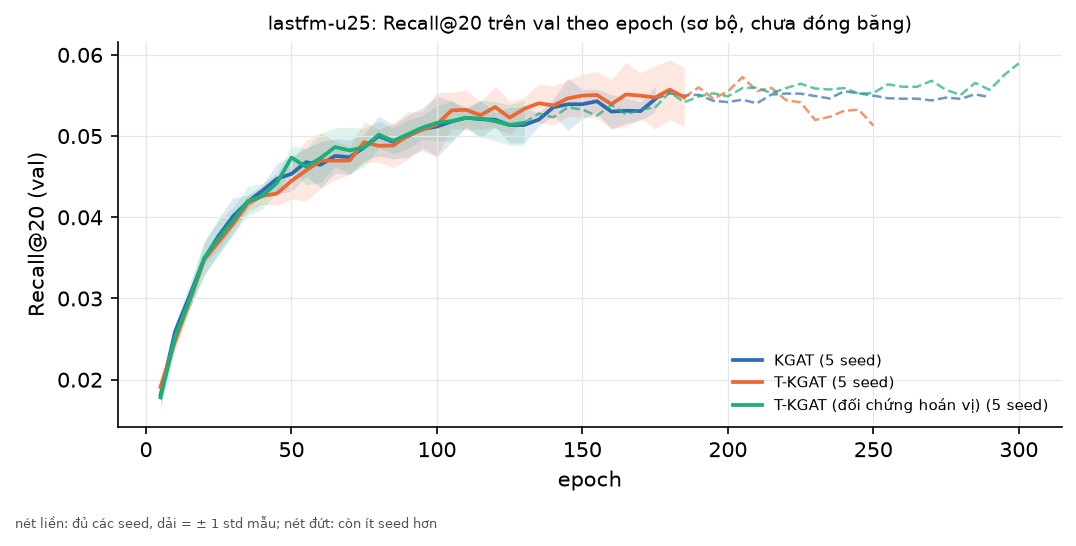

In [13]:
figure("rq3_curves_lastfm-u25.png", 720)

## 4. Kết quả và nhận xét
*Người trình bày: Triết*

> **Kết quả sơ bộ, chưa đóng băng (tag `v0.2-kgat`), chạy trước khi cô duyệt giao thức chia theo mốc.** `lastfm-u25` là 25% user của Last-FM, không phải Last-FM đầy đủ.

Bảng, kiểm định và hình do `scripts/10_rq3_table.py` và `scripts/09_significance.py` ghi (`results/rq3_models.csv`, `results/rq3_pairs.csv`, `results/significance.csv`);
notebook chỉ đọc chúng. Recall@20 và NDCG@20 trên **test**, trung bình ± độ lệch chuẩn mẫu (ddof = 1) qua 5 seed:

In [15]:
PRELIMINARY = {"kgat", "kgat_nokg", "tkgat", "tkgat_perm", "tkgat_kg", "tkgat_kg_perm"}
models = pd.read_csv(ROOT / "results/rq3_models.csv")
models = models[models["dataset"] == DS]
pairs = pd.read_csv(ROOT / "results/rq3_pairs.csv")
pairs = pairs[pairs["dataset"] == DS]


def sample_std(row, metric):
    return None if pd.isna(row[f"{metric}_std"]) else row[f"{metric}_std"]


rows = []
for _, r in models.iterrows():
    ok = r["status"] == "ok"
    rows.append(
        {
            "mô hình": r["label"] + (" [sơ bộ]" if r["model"] in PRELIMINARY else ""),
            "điểm chọn trên val": r["point"] if ok else "—",
            "Recall@20 (test)": vn_pm(r["recall@20_mean"], sample_std(r, "recall@20")) if ok else NOT_RUN,
            "NDCG@20 (test)": vn_pm(r["ndcg@20_mean"], sample_std(r, "ndcg@20")) if ok else NOT_RUN,
            "số seed": int(r["n_seeds"]) if ok else "—",
        }
    )
say(f"**{DS}** (user test: {int(models['n_users'].iloc[0])})")
show(pd.DataFrame(rows))

**lastfm-u25** (user test: 1608)

mô hình,điểm chọn trên val,Recall@20 (test),NDCG@20 (test),số seed
MostPop,window_days = None,"0,0238","0,0191",1
MostPop recent,window_days = 14,"0,0211","0,0169",1
BPR-MF,"dim = 64, l2 = 0.001, lr = 0.001","0,0520 ± 0,0028","0,0435 ± 0,0030",5
KGAT [sơ bộ],"l2 = 1e-05, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1","0,0534 ± 0,0008","0,0444 ± 0,0008",5
KGAT không KG [sơ bộ],"l2 = 1e-05, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1","0,0518 ± 0,0016","0,0426 ± 0,0004",5
T-KGAT [sơ bộ],"gamma = 10, l2 = 1e-05, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1","0,0529 ± 0,0025","0,0431 ± 0,0016",5
T-KGAT (đối chứng hoán vị) [sơ bộ],"gamma = 10, l2 = 1e-05, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1","0,0534 ± 0,0024","0,0441 ± 0,0017",5
T-KGAT giai đoạn 2 (Δt trên KG) [sơ bộ],"gamma = 1, l2 = 1e-05, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1, time_on = kg","0,0513 ± 0,0018","0,0426 ± 0,0014",5
T-KGAT giai đoạn 2 (đối chứng hoán vị ngày fact) [sơ bộ],"gamma = 1, l2 = 1e-05, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1, time_on = kg","0,0537 ± 0,0020","0,0436 ± 0,0016",5


**Kiểm định cặp theo user** (Wilcoxon, trung bình các seed chung; hiệu = trước − sau; p Holm trong cùng bộ dữ liệu và metric; `n_nonzero` là cỡ mẫu hiệu dụng):

In [16]:
rows = []
for _, r in pairs.iterrows():
    ok = r["status"] == "ok"
    note = r.get("warning") if ok else r["status"]
    rows.append(
        {
            "so sánh": r["pair"],
            "metric": r["metric"],
            "n_pairs": int(r["n_pairs"]) if ok else "—",
            "n_nonzero": int(r["n_nonzero"]) if ok else "—",
            "hiệu trung bình": num(r["mean_diff"]) if ok else "—",
            "p thô": vn_p(r["p_raw"]) if ok else "—",
            "p Holm": vn_p(r["p_holm"]) if ok else "—",
            "ghi chú": note if isinstance(note, str) else "(không cảnh báo)",
        }
    )
show(pd.DataFrame(rows))

so sánh,metric,n_pairs,n_nonzero,hiệu trung bình,p thô,p Holm,ghi chú
T-KGAT so với KGAT,recall@20,1608,682,"-0,0005","0,140","0,420",(không cảnh báo)
T-KGAT thật so với hoán vị,recall@20,1608,720,"-0,0005","0,675","0,803",(không cảnh báo)
KGAT so với KGAT không KG,recall@20,1608,783,"0,0016","0,402","0,803",(không cảnh báo)
T-KGAT giai đoạn 2 so với KGAT,recall@20,1608,745,"-0,0021","0,184","0,278",(không cảnh báo)
T-KGAT giai đoạn 2 thật so với hoán vị,recall@20,1608,651,"-0,0024","0,139","0,278",(không cảnh báo)
T-KGAT so với KGAT,ndcg@20,1608,901,"-0,0012","0,077","0,230",(không cảnh báo)
T-KGAT thật so với hoán vị,ndcg@20,1608,910,"-0,0009","0,381","0,506",(không cảnh báo)
KGAT so với KGAT không KG,ndcg@20,1608,929,"0,0017","0,253","0,506",(không cảnh báo)
T-KGAT giai đoạn 2 so với KGAT,ndcg@20,1608,921,"-0,0018","0,523","0,523",(không cảnh báo)
T-KGAT giai đoạn 2 thật so với hoán vị,ndcg@20,1608,878,"-0,0010","0,221","0,442",(không cảnh báo)


**Baseline** (`results/significance.csv`; hiệu = mô hình A − mô hình B; MostPop và MostPop recent chỉ có một lần chạy):

In [17]:
sig = pd.read_csv(ROOT / "results/significance.csv")
sig = sig[sig["dataset"] == DS]
cols = [
    "metric",
    "model_a",
    "model_b",
    "n_seeds_a",
    "n_pairs",
    "n_nonzero",
    "mean_diff",
    "p_raw",
    "p_holm",
]
show(
    sig[cols]
    .fillna("")
    .assign(
        mean_diff=lambda d: d["mean_diff"].map(lambda x: num(x) if x != "" else x),
        p_raw=lambda d: d["p_raw"].map(lambda x: vn_p(x) if x != "" else x),
        p_holm=lambda d: d["p_holm"].map(lambda x: vn_p(x) if x != "" else x),
    )
)

metric,model_a,model_b,n_seeds_a,n_pairs,n_nonzero,mean_diff,p_raw,p_holm
recall@20,bprmf,mostpop,5,1608,829,"0,0283","< 0,001","< 0,001"
recall@20,bprmf,mostpop_recent,5,1608,833,"0,0310","< 0,001","< 0,001"
recall@20,mostpop,mostpop_recent,1,1608,242,"0,0027","0,103","0,103"
ndcg@20,bprmf,mostpop,5,1608,847,"0,0244","< 0,001","< 0,001"
ndcg@20,bprmf,mostpop_recent,5,1608,846,"0,0266","< 0,001","< 0,001"
ndcg@20,mostpop,mostpop_recent,1,1608,314,"0,0022","0,016","0,016"


**Nhận xét** (các số trong lời đọc được tính từ đúng các bảng trên):

In [18]:
mm = models.set_index("model")


def mean(model, metric="recall@20"):
    return mm.loc[model, f"{metric}_mean"]


def std(model, metric="recall@20"):
    return mm.loc[model, f"{metric}_std"]


def holm(a, b, metric):
    r = pairs[(pairs["model_a"] == a) & (pairs["model_b"] == b) & (pairs["metric"] == metric)].iloc[0]
    return vn_p(r["p_holm"]), num(r["mean_diff"])


def base(a, b, metric):
    r = sig[(sig["model_a"] == a) & (sig["model_b"] == b) & (sig["metric"] == metric)].iloc[0]
    return vn_p(r["p_holm"])


n_users = int(models["n_users"].iloc[0])
sel_window = models.set_index("model").loc["mostpop_recent", "point"]
p_tk, d_tk = holm("tkgat", "kgat", "recall@20")
p_tk_n, d_tk_n = holm("tkgat", "kgat", "ndcg@20")
p_tp, d_tp = holm("tkgat", "tkgat_perm", "recall@20")
p_tp_n, d_tp_n = holm("tkgat", "tkgat_perm", "ndcg@20")
p_kn, d_kn = holm("kgat", "kgat_nokg", "recall@20")
p_kn_n, d_kn_n = holm("kgat", "kgat_nokg", "ndcg@20")
p_s2, d_s2 = holm("tkgat_kg", "kgat", "recall@20")
p_s2_n, _ = holm("tkgat_kg", "kgat", "ndcg@20")
p_s2p, d_s2p = holm("tkgat_kg", "tkgat_kg_perm", "recall@20")
p_s2p_n, _ = holm("tkgat_kg", "tkgat_kg_perm", "ndcg@20")
nz = pairs["n_nonzero"]
say(
    f"""
**1. Baseline.** BPR-MF đạt Recall@20 {num(mean("bprmf"))} so với MostPop {num(mean("mostpop"))}, và thắng cả MostPop
lẫn MostPop recent rất có ý nghĩa
(p Holm {base("bprmf", "mostpop", "recall@20")} và {base("bprmf", "mostpop_recent", "recall@20")}). **MostPop recent**
(cửa sổ chọn trên val: {sel_window}) đạt {num(mean("mostpop_recent"))},
**thấp hơn** MostPop thường (NDCG@20: p Holm {base("mostpop", "mostpop_recent", "ndcg@20")}). Giải thích chỉ là giả
thuyết, chưa kiểm:
cửa sổ neo ở cuối train, còn test bắt đầu ở t2, sau t1 khá lâu.

**2. KG (RQ2).** KGAT {num(mean("kgat"))} ± {num(std("kgat"))} so với KGAT không KG {num(mean("kgat_nokg"))} ±
{num(std("kgat_nokg"))}: hiệu {d_kn} Recall@20 và {d_kn_n} NDCG@20,
**không có ý nghĩa** (p Holm {p_kn} và {p_kn_n}). KGAT cũng chỉ hơn BPR-MF ({num(mean("bprmf"))} ±
{num(std("bprmf"))}) {num(mean("kgat") - mean("bprmf"))}, nhỏ hơn độ lệch chuẩn qua seed của BPR-MF;
cặp này **chưa nằm trong họ kiểm định** nên chưa có p. **Chưa có bằng chứng KG giúp trên Last-FM.**

**3. Thời gian, Stage 1 (RQ3).** T-KGAT {num(mean("tkgat"))} ± {num(std("tkgat"))}; KGAT {num(mean("kgat"))}; bản hoán
vị {num(mean("tkgat_perm"))} ± {num(std("tkgat_perm"))}.
T-KGAT so với KGAT: hiệu {d_tk} / {d_tk_n}, p Holm {p_tk} / {p_tk_n}. T-KGAT thật so với hoán vị: hiệu {d_tp} /
{d_tp_n}, p Holm {p_tp} / {p_tp_n}.
**Chưa có bằng chứng thời gian trên cạnh user–item giúp**, và bản hoán vị không kém bản thật.

**4. Thời gian, Stage 2.** Stage 2 {num(mean("tkgat_kg"))} ± {num(std("tkgat_kg"))}; bản hoán vị ngày fact
{num(mean("tkgat_kg_perm"))} ± {num(std("tkgat_kg_perm"))}.
So với KGAT: hiệu {d_s2}, p Holm {p_s2} / {p_s2_n}; so với bản hoán vị: hiệu {d_s2p}, p Holm {p_s2p} / {p_s2p_n}.
Thang Δt của KG ở đây có độ phân giải (phần 2) nên đây là phép đo thật
cho "fact cũ hay mới", dù phần lớn fact có ngày vẫn bị chặn ở 1. Lưu ý so sánh với KGAT là giữa hai máy.

**Mức độ chắc chắn.** Test có {n_users} user và `n_nonzero` từ {int(nz.min())} đến {int(nz.max())}, không có cảnh báo
cỡ mẫu: kiểm định đủ sức để nói chênh lệch (nếu có) nhỏ,
nhỏ hơn độ nhiễu qua seed. Đây vẫn **không** phải bằng chứng "bằng nhau".
"""
)


**1. Baseline.** BPR-MF đạt Recall@20 0,0520 so với MostPop 0,0238, và thắng cả MostPop
lẫn MostPop recent rất có ý nghĩa
(p Holm < 0,001 và < 0,001). **MostPop recent**
(cửa sổ chọn trên val: window_days = 14) đạt 0,0211,
**thấp hơn** MostPop thường (NDCG@20: p Holm 0,016). Giải thích chỉ là giả
thuyết, chưa kiểm:
cửa sổ neo ở cuối train, còn test bắt đầu ở t2, sau t1 khá lâu.

**2. KG (RQ2).** KGAT 0,0534 ± 0,0008 so với KGAT không KG 0,0518 ±
0,0016: hiệu 0,0016 Recall@20 và 0,0017 NDCG@20,
**không có ý nghĩa** (p Holm 0,803 và 0,506). KGAT cũng chỉ hơn BPR-MF (0,0520 ±
0,0028) 0,0013, nhỏ hơn độ lệch chuẩn qua seed của BPR-MF;
cặp này **chưa nằm trong họ kiểm định** nên chưa có p. **Chưa có bằng chứng KG giúp trên Last-FM.**

**3. Thời gian, Stage 1 (RQ3).** T-KGAT 0,0529 ± 0,0025; KGAT 0,0534; bản hoán
vị 0,0534 ± 0,0024.
T-KGAT so với KGAT: hiệu -0,0005 / -0,0012, p Holm 0,420 / 0,230. T-KGAT thật so với hoán vị: hiệu -0,0005 /
-0,0009, p Holm 0,803 / 0,506.
**Chưa có bằng chứng thời gian trên cạnh user–item giúp**, và bản hoán vị không kém bản thật.

**4. Thời gian, Stage 2.** Stage 2 0,0513 ± 0,0018; bản hoán vị ngày fact
0,0537 ± 0,0020.
So với KGAT: hiệu -0,0021, p Holm 0,278 / 0,523; so với bản hoán vị: hiệu -0,0024, p Holm 0,278 / 0,442.
Thang Δt của KG ở đây có độ phân giải (phần 2) nên đây là phép đo thật
cho "fact cũ hay mới", dù phần lớn fact có ngày vẫn bị chặn ở 1. Lưu ý so sánh với KGAT là giữa hai máy.

**Mức độ chắc chắn.** Test có 1608 user và `n_nonzero` từ 651 đến 929, không có cảnh báo
cỡ mẫu: kiểm định đủ sức để nói chênh lệch (nếu có) nhỏ,
nhỏ hơn độ nhiễu qua seed. Đây vẫn **không** phải bằng chứng "bằng nhau".


## 5. Minh bạch và hạn chế
*Người trình bày: Triết*

In [19]:
if HAVE_DATA:
    t2 = int(meta["t2"])
    val_days = (t2 - t1) / 86400
    test_days = (int(pd.read_csv(ROOT / f"data/processed/{DS}/test.csv")["ts"].max()) - t2) / 86400
    span = (
        f"train {num((t_ref - t_min) / 86400, 0)} ngày, val {num(val_days, 0)} ngày, test {num(test_days, 0)} "
        "ngày (tính từ dữ liệu đã xử lý)"
    )
else:
    span = "(chưa có dữ liệu đã xử lý)"
say(
    f"""
**Phải báo rõ:**
1. Quyết định chuyển sang Last-FM được đưa ra **sau khi** điểm test MovieLens đã được xem (0012, phần Context ở trên).
2. KGAT và T-KGAT là **sơ bộ**: bảng RQ3 ghi "chạy trước khi cô duyệt giao thức"; chưa có tag `v0.2-kgat`; PR #42 còn
  là bản nháp và chưa tái lập độc lập từ clone sạch (tình trạng ngày 12/11/2026, cập nhật tay nếu đã đổi).
3. Stage 2 chạy trên máy khác (Kaggle T4); cổng đo thời gian và ước lượng giờ chạy: xem quyết định 0014
  (bản đầy đủ của notebook, phần 3).
4. Các phân tích bổ sung đã đề xuất với cô (0014, Consequences) **chưa chạy**; mỗi cái cần quyết định riêng và sẽ được
  ghi là thêm sau khi đã thấy test.

**Hạn chế:**
1. Tập cặp (user, item) của KGAT được chọn bằng thông tin sau 01/04/2014; ảnh hưởng chưa đo (phần 2).
2. Chỉ {V("lastfm-u25.user_fraction")} user; mất {V("lastfm-u25.val_dropped_cold_item_share")} val và
  {V("lastfm-u25.test_dropped_cold_item_share")} test vì cold item; không nói cho toàn Last-FM.
3. Timestamp là lần nghe sớm nhất của cặp; độ dài khoảng thời gian rất lệch nhau: {span}.
4. Freebase là bản chụp {V("conv.freebase_snapshot")}; KG không có ngày của statement;
  {V("lastfm-u25.kg.undated_t1_share")} fact không có ngày; KG t1 = KG t2 nên không kiểm được rò rỉ giữa hai mốc.
5. KGAT không tái lập từng bit trên GPU; chưa tái lập độc lập.
6. Điểm được chọn nằm ở mép lưới; hoán vị toàn cục chỉ là một dạng đối chứng (hoán vị theo khối thời gian chưa chạy).
7. Stage 2 so với KGAT là so giữa hai máy; BPR-MF so với KGAT chưa kiểm định.
8. Số của nhóm không so trực tiếp với số trong paper KGAT (chia theo thời gian, 5-core, 25% user, KG có ngày).
"""
)


**Phải báo rõ:**
1. Quyết định chuyển sang Last-FM được đưa ra **sau khi** điểm test MovieLens đã được xem (0012, phần Context ở trên).
2. KGAT và T-KGAT là **sơ bộ**: bảng RQ3 ghi "chạy trước khi cô duyệt giao thức"; chưa có tag `v0.2-kgat`; PR #42 còn
  là bản nháp và chưa tái lập độc lập từ clone sạch (tình trạng ngày 12/11/2026, cập nhật tay nếu đã đổi).
3. Stage 2 chạy trên máy khác (Kaggle T4); cổng đo thời gian và ước lượng giờ chạy: xem quyết định 0014
  (bản đầy đủ của notebook, phần 3).
4. Các phân tích bổ sung đã đề xuất với cô (0014, Consequences) **chưa chạy**; mỗi cái cần quyết định riêng và sẽ được
  ghi là thêm sau khi đã thấy test.

**Hạn chế:**
1. Tập cặp (user, item) của KGAT được chọn bằng thông tin sau 01/04/2014; ảnh hưởng chưa đo (phần 2).
2. Chỉ 25% user; mất 28,8% val và
  28,1% test vì cold item; không nói cho toàn Last-FM.
3. Timestamp là lần nghe sớm nhất của cặp; độ dài khoảng thời gian rất lệch nhau: train 3361 ngày, val 39 ngày, test 86 ngày (tính từ dữ liệu đã xử lý).
4. Freebase là bản chụp 09/08/2015; KG không có ngày của statement;
  19,8% fact không có ngày; KG t1 = KG t2 nên không kiểm được rò rỉ giữa hai mốc.
5. KGAT không tái lập từng bit trên GPU; chưa tái lập độc lập.
6. Điểm được chọn nằm ở mép lưới; hoán vị toàn cục chỉ là một dạng đối chứng (hoán vị theo khối thời gian chưa chạy).
7. Stage 2 so với KGAT là so giữa hai máy; BPR-MF so với KGAT chưa kiểm định.
8. Số của nhóm không so trực tiếp với số trong paper KGAT (chia theo thời gian, 5-core, 25% user, KG có ngày).


## 6. Ba vấn đề của `lastfm-u25` và bản dữ liệu mới `lastfm-u25-latest`
*Người trình bày: Triết (6.0 và 6.1, đến hết đoạn "Bản `lastfm-u25-latest` sửa được gì?"), Phôn (từ 6.2)*

**`lastfm-u25-latest` là gì.** Cùng mẫu user (cùng seed), cùng cách đặt t1/t2 theo phân vị, cùng k-core chỉ trên train, cùng
quy trình KG, cùng lưới, cùng các seed (số liệu cụ thể ở 6.2). **Chỉ một thứ đổi: timestamp của cặp (user, item) là lần nghe MUỘN nhất** (thay vì sớm nhất)
trong LFM-1b. Tập cặp vẫn là tập cặp của KGAT. Code xuất dữ liệu, các dòng registry và quyết định 0015 là của Phôn; **chưa nằm
trong repo này** (xem 6.0), nên số liệu bên dưới là sơ bộ và chưa tái lập được chỉ từ repo.

**6.0. Nguồn số liệu của phần 6**

In [20]:
import yaml

DSL = "lastfm-u25-latest"
LDIR = ROOT / "data/processed" / DSL
HAVE_LATEST = (LDIR / "meta.json").exists()
NUMSL = parse_numbers(read_text("docs/data-report-lastfm-latest-numbers.md"))
PROV = json.loads(read_text("results/lastfm-latest-provenance.json"))
LM = pd.read_csv(ROOT / "results/rq3_models_lastfm-latest.csv")
LP = pd.read_csv(ROOT / "results/rq3_pairs_lastfm-latest.csv")
GAMMA_GRID = [pt["gamma"] for pt in yaml.safe_load(read_text("configs/model/tkgat.yaml"))["grid"]]
GRID_TEXT = "{" + ", ".join(str(g) for g in GAMMA_GRID) + "}"


def VL(key):
    # a number or text of docs/data-report-lastfm-latest-numbers.md (key without the run prefix), as the script wrote it
    full = f"{DSL}.{key}"
    if full not in NUMSL:
        raise KeyError(f"{full!r} is not in docs/data-report-lastfm-latest-numbers.md")
    return NUMSL[full][0]


def dmy(ts):
    return pd.Timestamp(int(ts), unit="s", tz="UTC").strftime("%d/%m/%Y")


def days(x):
    return f"{x:,.0f}".replace(",", ".")


n_repo_rows = int((REG_ALL["dataset"] == DSL).sum())
decisions_0015 = sorted((ROOT / "docs/decisions").glob("0015-*.md"))
say(
    f"> Phần 6 đọc `docs/data-report-lastfm-latest-numbers.md` ({len(NUMSL)} khóa), "
    "`results/rq3_models_lastfm-latest.csv`, `results/rq3_pairs_lastfm-latest.csv` và `results/lastfm-latest-provenance.json`: "  # noqa: E501
    f"registry gộp của **{len(PROV['zips'])}** zip kết quả của Phôn có **{PROV['registry_rows_all_zips']}** dòng, "
    f"**{PROV['registry_rows_distinct']}** dòng riêng biệt, commit {', '.join(PROV['git_commits'])} (lịch sử riêng, không nằm "  # noqa: E501
    f"trong repo), **{PROV['dirty_rows']}** dòng `-dirty`. "
    f"`results/registry.csv` của repo có **{n_repo_rows}** dòng `{DSL}` (không thêm dòng nào). "
    f"File quyết định `0015-*.md` trong repo: **{len(decisions_0015)}** (0015 là bản nháp của Phôn, chưa được duyệt). "
    f"Thiết bị: {', '.join(sorted(set(k.removeprefix(f'{DSL}.hours.device.') for k in NUMSL if k.startswith(f'{DSL}.hours.device.'))))}."  # noqa: E501
)
if not HAVE_LATEST:
    say(f'**Chưa có `data/processed/{DSL}/`:** các ô đọc dữ liệu đã xử lý của phần 6 sẽ báo "chưa có".')

> Phần 6 đọc `docs/data-report-lastfm-latest-numbers.md` (86 khóa), `results/rq3_models_lastfm-latest.csv`, `results/rq3_pairs_lastfm-latest.csv` và `results/lastfm-latest-provenance.json`: registry gộp của **5** zip kết quả của Phôn có **323** dòng, **132** dòng riêng biệt, commit 873ca7f (lịch sử riêng, không nằm trong repo), **0** dòng `-dirty`. `results/registry.csv` của repo có **0** dòng `lastfm-u25-latest` (không thêm dòng nào). File quyết định `0015-*.md` trong repo: **0** (0015 là bản nháp của Phôn, chưa được duyệt). Thiết bị: Tesla_T4, cpu.

### 6.1. Ba vấn đề của `lastfm-u25`

Phần 2 đã nêu hạn chế của tập cặp. Ở đây gom thành ba vấn đề, mỗi vấn đề kèm bằng chứng đọc từ file:
**A** tập cặp được chọn bằng thông tin sau 01/04/2014; **B** số cạnh train nhảy lên quanh 01/04/2014; **C** `check_split` không thấy được A và B.

In [21]:
def split_problems(run):
    s, _ = load_saved({"processed_dir": str(ROOT / "data/processed" / run)})
    return len(check_split(s))


if HAVE_DATA:
    tr_u25 = pd.read_csv(ROOT / f"data/processed/{DS}/train.csv")
    apr1 = pd.Timestamp("2014-04-01", tz="UTC").timestamp()
    share_from_apr = float((tr_u25["ts"] >= apr1).mean())
    window_days_u25 = (tr_u25["ts"].max() - tr_u25["ts"].min()) / 86400
    before, after = as_int(V(f"{DS}.week.before_mean")), as_int(V(f"{DS}.week.after_mean"))
    say(
        f"""
- **A. Tập cặp chọn bằng thông tin sau 01/04/2014** (quyết định 0012, mục Pair selection; nguyên văn ở bản đầy đủ của notebook, phần 2). Tập cặp mà tác giả KGAT công bố chỉ
  chứa cặp còn được nghe từ 01/04/2014; nghĩa là cặp nào "sống" đến cuối giai đoạn mới có mặt. Đó là thông tin sau mốc t1
  ({V(f"{DS}.t1")}) và t2 ({V(f"{DS}.t2")}), có thể thiên vị các cặp sống lâu. Tác động lên kết quả **chưa đo**.
- **B. Bước nhảy số cạnh quanh 01/04/2014** (dấu vết nhìn thấy của A, đọc từ `train.csv` của `{DS}`): trung bình {V(f"{DS}.week.before_mean")}
  cạnh mỗi tuần trong 4 tuần trước 31/03/2014 và {V(f"{DS}.week.after_mean")} trong 4 tuần từ đó (gấp {num(after / before, 1)} lần);
  {pct(share_from_apr)} cạnh train có timestamp từ 01/04/2014 trở đi, dù cửa sổ train dài {days(window_days_u25)} ngày.
- **C. `check_split` không thấy được A và B.** Trên `{DS}` nó báo **{split_problems(DS)}** vấn đề: lỗi nằm **trước** khi chia, nên các kiểm tra
  về thứ tự thời gian, mask và k-core đều qua.
"""  # noqa: E501
    )
else:
    say("*chưa có: cần `data/processed/lastfm-u25/`.*")


- **A. Tập cặp chọn bằng thông tin sau 01/04/2014** (quyết định 0012, mục Pair selection; nguyên văn ở bản đầy đủ của notebook, phần 2). Tập cặp mà tác giả KGAT công bố chỉ
  chứa cặp còn được nghe từ 01/04/2014; nghĩa là cặp nào "sống" đến cuối giai đoạn mới có mặt. Đó là thông tin sau mốc t1
  (29/04/2014) và t2 (07/06/2014), có thể thiên vị các cặp sống lâu. Tác động lên kết quả **chưa đo**.
- **B. Bước nhảy số cạnh quanh 01/04/2014** (dấu vết nhìn thấy của A, đọc từ `train.csv` của `lastfm-u25`): trung bình 2.494
  cạnh mỗi tuần trong 4 tuần trước 31/03/2014 và 12.416 trong 4 tuần từ đó (gấp 5,0 lần);
  21,7% cạnh train có timestamp từ 01/04/2014 trở đi, dù cửa sổ train dài 3.361 ngày.
- **C. `check_split` không thấy được A và B.** Trên `lastfm-u25` nó báo **0** vấn đề: lỗi nằm **trước** khi chia, nên các kiểm tra
  về thứ tự thời gian, mask và k-core đều qua.


**Bản `lastfm-u25-latest` sửa được gì?** Đổi timestamp từ lần nghe sớm nhất sang lần nghe muộn nhất làm bước nhảy B biến mất (6.3)
vì mọi timestamp đều từ 01/04/2014. Nhưng tập cặp vẫn là tập cặp của KGAT nên **A còn nguyên**, và `check_split` vẫn không thấy
(C, xem ô dưới). Phần bên dưới đo xem bản latest **đổi hình thức** thiên lệch ra sao và điều đó ảnh hưởng gì tới Stage 1 và Stage 2.

### 6.2. So sánh `lastfm-u25` và `lastfm-u25-latest`
*Người trình bày: Phôn*

Số của `lastfm-u25` đọc từ `docs/data-report-lastfm-numbers.md`, số của `lastfm-u25-latest` từ
`docs/data-report-lastfm-latest-numbers.md`; độ dài train/val/test và cửa sổ train tính từ `train.csv`, `meta.json`, `test.csv` của từng run:

In [22]:
def spans(run):
    # train window, val and test lengths in days, computed from the processed files of one run
    pdir = ROOT / "data/processed" / run
    m = json.loads((pdir / "meta.json").read_text(encoding="utf-8"))
    tr_ts = pd.read_csv(pdir / "train.csv", usecols=["ts"])["ts"]
    te_ts = pd.read_csv(pdir / "test.csv", usecols=["ts"])["ts"]
    return {
        "train": (tr_ts.max() - tr_ts.min()) / 86400,
        "val": (m["t2"] - m["t1"]) / 86400,
        "test": (te_ts.max() - m["t2"]) / 86400,
        "first": tr_ts.min(),
        "last": tr_ts.max(),
    }


def column(run, get):
    return {
        "cặp (user, item)": get(f"{run}.pairs"),
        "timestamp của cặp": "lần nghe sớm nhất" if run == DS else "lần nghe muộn nhất",
        "t1 / t2": f"{get(f'{run}.t1')} / {get(f'{run}.t2')}",
        "user / item train": f"{get(f'{run}.users')} / {get(f'{run}.items')}",
        "positive train": get(f"{run}.train_pos"),
        "positive val (user)": f"{get(f'{run}.val_pos')} ({get(f'{run}.val_users')})",
        "positive test (user)": f"{get(f'{run}.test_pos')} ({get(f'{run}.test_users')})",
        "val mất vì cold item": get(f"{run}.val_dropped_cold_item_share"),
        "test mất vì cold item": get(f"{run}.test_dropped_cold_item_share"),
        "val / test mất vì cold user": f"{get(f'{run}.val_dropped_cold_user_share')} / {get(f'{run}.test_dropped_cold_user_share')}",  # noqa: E501
        "positive bị 5-core loại khỏi train": get(f"{run}.kcore_removed"),
        "KG default tại t1 (triple)": get(f"{run}.kg.default.t1"),
        "KG: thực thể / % triple không ngày": f"{get(f'{run}.kg.entities')} / {get(f'{run}.kg.undated_t1_share')}",
        "cửa sổ train theo Δt (năm)": get(f"{run}.dt.window_years"),
    }


if HAVE_DATA and HAVE_LATEST:
    sp_u, sp_l = spans(DS), spans(DSL)
    cols = {
        "lastfm-u25": column(DS, V),
        "lastfm-u25-latest": column(DSL, lambda key: NUMSL[key][0]),
    }
    for label, sp in (("lastfm-u25", sp_u), ("lastfm-u25-latest", sp_l)):
        cols[label]["train: từ ngày – đến ngày"] = f"{dmy(sp['first'])} – {dmy(sp['last'])}"
        cols[label]["train / val / test (ngày)"] = f"{days(sp['train'])} / {days(sp['val'])} / {days(sp['test'])}"
    table6 = pd.DataFrame(cols)
    display(table6)
    # the computed lengths must agree with what script 11 wrote for the latest dataset
    assert days(sp_l["train"]) == VL("edge.window_days"), (sp_l["train"], VL("edge.window_days"))
    assert dmy(sp_l["first"]) == VL("edge.first_day")
    say(
        f"**Đọc:** hai bản có **cùng** {V(f'{DS}.pairs')} cặp và cùng số user được lấy mẫu ({V(f'{DS}.users_sampled')}), nhưng t1/t2 khác hẳn "  # noqa: E501
        f"({V(f'{DS}.t1')} so với {VL('t1')}), vì timestamp đổi. Cửa sổ train của latest chỉ **{days(sp_l['train'])} ngày** "  # noqa: E501
        f"(`{dmy(sp_l['first'])}` đến `{dmy(sp_l['last'])}`), so với {days(sp_u['train'])} ngày của `{DS}`; val {days(sp_l['val'])} ngày và test "  # noqa: E501
        f"{days(sp_l['test'])} ngày (u25: {days(sp_u['val'])} và {days(sp_u['test'])}). Cold item mất {VL('val_dropped_cold_item_share')} val và "  # noqa: E501
        f"{VL('test_dropped_cold_item_share')} test (u25: {V(f'{DS}.val_dropped_cold_item_share')} và {V(f'{DS}.test_dropped_cold_item_share')}). "  # noqa: E501
        f"Số user test là {VL('test_users')} (u25: {V(f'{DS}.test_users')}). "
        "Payload dữ liệu của Phôn chỉ có biến thể KG `default`, nên không có cột `drop_undated` và `static` cho latest."
    )
    say(
        f"**Kiểm tra không rò rỉ trên latest:** `check_split` báo **{split_problems(DSL)}** vấn đề trên `{DSL}` "
        "(cùng hàm, đọc từ file đã lưu). Như đã nói ở C, con số 0 này không chứng minh tập cặp không thiên lệch."
    )
else:
    say("*chưa có: cần `data/processed/lastfm-u25/` và `data/processed/lastfm-u25-latest/`.*")

,lastfm-u25,lastfm-u25-latest
"cặp (user, item)",370.979,370.979
timestamp của cặp,lần nghe sớm nhất,lần nghe muộn nhất
t1 / t2,29/04/2014 / 07/06/2014,23/06/2014 / 19/07/2014
user / item train,5.321 / 18.665,5.367 / 19.165
positive train,236.053,236.339
positive val (user),23.708 (2.319),25.860 (1.516)
positive test (user),22.419 (1.608),24.244 (1.341)
val mất vì cold item,"28,8%","24,2%"
test mất vì cold item,"28,1%","21,9%"
val / test mất vì cold user,"7,3% / 11,5%","6,1% / 12,8%"


**Đọc:** hai bản có **cùng** 370.979 cặp và cùng số user được lấy mẫu (5.892 / 23.566), nhưng t1/t2 khác hẳn (29/04/2014 so với 23/06/2014), vì timestamp đổi. Cửa sổ train của latest chỉ **83 ngày** (`01/04/2014` đến `23/06/2014`), so với 3.361 ngày của `lastfm-u25`; val 26 ngày và test 45 ngày (u25: 39 và 86). Cold item mất 24,2% val và 21,9% test (u25: 28,8% và 28,1%). Số user test là 1.341 (u25: 1.608). Payload dữ liệu của Phôn chỉ có biến thể KG `default`, nên không có cột `drop_undated` và `static` cho latest.

**Kiểm tra không rò rỉ trên latest:** `check_split` báo **0** vấn đề trên `lastfm-u25-latest` (cùng hàm, đọc từ file đã lưu). Như đã nói ở C, con số 0 này không chứng minh tập cặp không thiên lệch.

### 6.3. Stage 1: thời gian của cạnh train

Số cạnh train theo tuần (trái: `lastfm-u25`, timestamp = lần nghe sớm nhất; phải: `lastfm-u25-latest`, timestamp = lần nghe muộn nhất).
Đường đỏ là 01/04/2014:

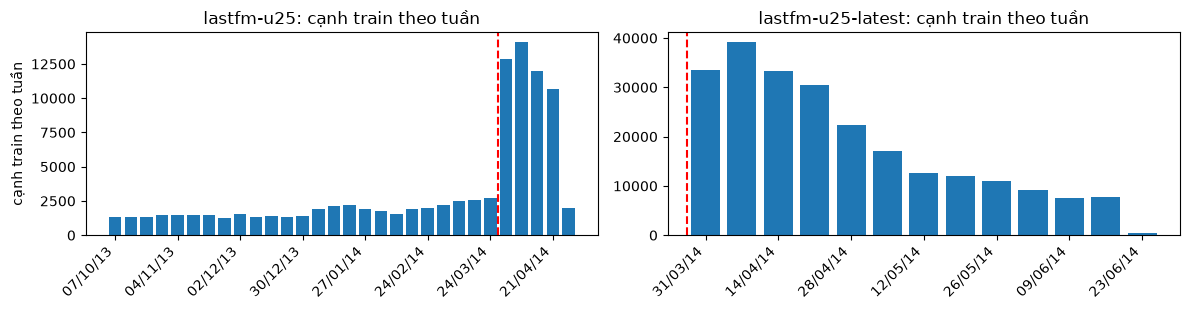

,lastfm-u25,lastfm-u25-latest
chỉ tiêu (cạnh train),,
"độ dài cửa sổ (dt_den, ngày)",3.361,83
trung vị dt_norm,"0,10","0,73"
"dt_norm < 0,25","78,8%","10,2%"
cạnh trong 7 ngày cuối,"4,3%","3,3%"
cạnh trong 30 ngày cuối,"22,0%","16,2%"
user có mọi cạnh train trong < 1 giờ,"0,53%","0,93%"
trung vị độ lệch chuẩn thời gian theo user (ngày),"249,6","9,2"


**Đọc (tính từ các số trên):** trong latest không còn bước nhảy quanh 01/04/2014: ngày đầu của train là 01/04/2014, tuần đầy đủ đầu tiên có 39.197 cạnh và tuần đầy đủ cuối cùng có 7.717 (số cạnh theo tuần giảm dần về cuối cửa sổ; nguyên nhân chưa kiểm). Δt vẫn có biến thiên (trung vị độ lệch chuẩn theo user 9,2 ngày, chỉ 0,93% user có mọi cạnh trong 1 giờ), nhưng trên cửa sổ **83 ngày** thay vì 3.361 ngày: **một đơn vị `dt_norm` là 83 ngày** (u25: một đơn vị là cả cửa sổ 3.361 ngày), nên cùng γ trong lưới {1, 3, 10} không có cùng nghĩa theo ngày trên hai bản.

**Hình thức thiên lệch đổi chứ không mất** *(suy từ định nghĩa của timestamp, không phải số đo)*: với timestamp là lần nghe muộn nhất, một cặp (trước khi lọc k-core và cold-start) nằm trong train **khi và chỉ khi** trong dữ liệu LFM-1b user không nghe cặp đó từ t1 trở đi; cặp nào còn được nghe sau t1 chỉ có thể nằm ở val hoặc test. Tức train chỉ chứa các cặp mà việc nghe đã dừng (trong dữ liệu có sẵn), và biết cặp nào còn được nghe sau t1 là thông tin sau mốc. Ở `lastfm-u25` thiên lệch nằm ở **tập cặp** (A); ở latest nó nằm thêm ở **việc cặp rơi vào phần nào** của phép chia. Tác động của nó lên kết quả **chưa đo**.

In [23]:
def edge_stats(run):
    # Delta-t of the train edges as tkgat.kg.ckg.build_ckg defines it: t_ref = max train ts, dt_den = max - min
    train = pd.read_csv(ROOT / "data/processed" / run / "train.csv")
    ts = train["ts"].to_numpy(dtype="float64")
    t_ref, dt_den = ts.max(), ts.max() - ts.min()
    x = (t_ref - ts) / dt_den
    return {
        "train": train,
        "dt_den_days": dt_den / 86400,
        "median": float(pd.Series(x).median()),
        "below_0_25": float((x < 0.25).mean()),
        "last7": float(((t_ref - ts) < 7 * 86400).mean()),
        "last30": float(((t_ref - ts) < 30 * 86400).mean()),
    }


if HAVE_DATA and HAVE_LATEST:
    es_u, es_l = edge_stats(DS), edge_stats(DSL)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
    for ax, (label, es, start) in zip(
        axes, (("lastfm-u25", es_u, "2013-10-01"), ("lastfm-u25-latest", es_l, "2014-03-01")), strict=True
    ):
        weekly_x = eda.weekly_counts(es["train"])
        weekly_x = weekly_x[weekly_x.index >= start]
        ax.bar(range(len(weekly_x)), weekly_x.values, width=0.8)
        step = 4 if label == "lastfm-u25" else 2
        ax.set_xticks(range(0, len(weekly_x), step))
        ax.set_xticklabels([d.strftime("%d/%m/%y") for d in weekly_x.index[::step]], rotation=45, ha="right")
        marker = pd.Timestamp("2014-03-31")  # Monday of the week that contains 2014-04-01
        if marker in weekly_x.index:
            pos = list(weekly_x.index).index(marker)
            ax.axvline(pos - 0.5, color="red", ls="--")
        ax.set_title(f"{label}: cạnh train theo tuần")
    axes[0].set_ylabel("cạnh train theo tuần")
    plt.tight_layout()
    plt.show()
    # the numbers of the latest dataset must agree with what script 11 wrote
    assert num(es_l["median"], 2) == VL("edge.dt_norm_median")
    assert pct(es_l["last7"]) == VL("edge.last_7d_share") and pct(es_l["last30"]) == VL("edge.last_30d_share")
    assert pct(es_l["below_0_25"]) == VL("edge.dt_norm_below_0_25")
    rows = [
        {
            "chỉ tiêu (cạnh train)": "độ dài cửa sổ (dt_den, ngày)",
            "lastfm-u25": days(es_u["dt_den_days"]),
            "lastfm-u25-latest": VL("edge.window_days"),
        },
        {
            "chỉ tiêu (cạnh train)": "trung vị dt_norm",
            "lastfm-u25": num(es_u["median"], 2),
            "lastfm-u25-latest": VL("edge.dt_norm_median"),
        },
        {
            "chỉ tiêu (cạnh train)": "dt_norm < 0,25",
            "lastfm-u25": pct(es_u["below_0_25"]),
            "lastfm-u25-latest": VL("edge.dt_norm_below_0_25"),
        },
        {
            "chỉ tiêu (cạnh train)": "cạnh trong 7 ngày cuối",
            "lastfm-u25": pct(es_u["last7"]),
            "lastfm-u25-latest": VL("edge.last_7d_share"),
        },
        {
            "chỉ tiêu (cạnh train)": "cạnh trong 30 ngày cuối",
            "lastfm-u25": pct(es_u["last30"]),
            "lastfm-u25-latest": VL("edge.last_30d_share"),
        },
        {
            "chỉ tiêu (cạnh train)": "user có mọi cạnh train trong < 1 giờ",
            "lastfm-u25": V(f"{DS}.spread.user_under_1h"),
            "lastfm-u25-latest": VL("spread.user_under_1h"),
        },
        {
            "chỉ tiêu (cạnh train)": "trung vị độ lệch chuẩn thời gian theo user (ngày)",
            "lastfm-u25": V(f"{DS}.spread.user_std_days_median"),
            "lastfm-u25-latest": VL("spread.user_std_days_median"),
        },
    ]
    display(pd.DataFrame(rows).set_index("chỉ tiêu (cạnh train)"))
    say(
        f"**Đọc (tính từ các số trên):** trong latest không còn bước nhảy quanh 01/04/2014: ngày đầu của train là {VL('edge.first_day')}, "  # noqa: E501
        f"tuần đầy đủ đầu tiên có {VL('week.first_full')} cạnh và tuần đầy đủ cuối cùng có {VL('week.last_full')} (số cạnh theo tuần giảm dần về cuối cửa sổ; "  # noqa: E501
        "nguyên nhân chưa kiểm). "
        f"Δt vẫn có biến thiên (trung vị độ lệch chuẩn theo user {VL('spread.user_std_days_median')} ngày, chỉ {VL('spread.user_under_1h')} user có mọi cạnh trong 1 giờ), "  # noqa: E501
        f"nhưng trên cửa sổ **{VL('edge.window_days')} ngày** thay vì {days(es_u['dt_den_days'])} ngày: **một đơn vị `dt_norm` là {VL('edge.window_days')} ngày** "  # noqa: E501
        f"(u25: một đơn vị là cả cửa sổ {days(es_u['dt_den_days'])} ngày), nên cùng γ trong lưới "
        f"{GRID_TEXT} không có cùng nghĩa theo ngày trên hai bản."  # noqa: E501
    )
    say(
        "**Hình thức thiên lệch đổi chứ không mất** *(suy từ định nghĩa của timestamp, không phải số đo)*: với timestamp là lần nghe muộn nhất, "  # noqa: E501
        "một cặp (trước khi lọc k-core và cold-start) nằm trong train **khi và chỉ khi** trong dữ liệu LFM-1b user không nghe cặp đó từ t1 trở đi; "  # noqa: E501
        "cặp nào còn được nghe sau t1 chỉ có thể nằm ở val hoặc test. "
        "Tức train chỉ chứa các cặp mà việc nghe đã dừng (trong dữ liệu có sẵn), và biết cặp nào còn được nghe sau t1 là thông tin sau mốc. "  # noqa: E501
        "Ở `lastfm-u25` thiên lệch nằm ở **tập cặp** (A); ở latest nó nằm thêm ở **việc cặp rơi vào phần nào** của phép chia. Tác động của nó lên kết quả **chưa đo**."  # noqa: E501
    )
else:
    say("*chưa có: cần `data/processed/lastfm-u25/` và `data/processed/lastfm-u25-latest/`.*")

### 6.4. Stage 2: thang Δt của KG

Ngày của fact là ngày tồn tại của đích (từ bản chụp Freebase), không đổi giữa hai bản. Cái đổi là **cửa sổ train**: `dt_norm = (t_ref − ngày fact) / dt_den`
bị chặn ở 1, nên fact chỉ nằm trong cửa sổ nếu ngày của nó sau ngày đầu của train.

**Nguyên nhân là cách chuẩn hóa, không phải dữ liệu hỏng:** `dt_den` lấy theo cửa sổ của **tương tác** train (quyết định 0009, mục 3) và `dt_norm` của cạnh KG bị chặn ở 1 (mục 10), nên fact cũ hơn cửa sổ đều có `dt_norm` = 1. Stage 1 không bị vì cạnh tương tác luôn nằm trong cửa sổ. `lastfm-u25` cũng bị một phần (phần fact bị chặn ở 1, bảng dưới). Đề xuất: một quyết định mới chuẩn hóa Δt của fact theo ngày của fact, báo là thêm sau khi đã thấy test, rồi mới chạy lại Stage 2.

In [24]:
if HAVE_DATA and HAVE_LATEST:

    def fact_dates(run):
        d = pd.read_csv(ROOT / "data/processed" / run / "kg/default/kg_t1_dates.tsv", sep="\t")["ts"].dropna()
        return d.to_numpy(dtype="float64")

    fd_u, fd_l = fact_dates(DS), fact_dates(DSL)
    rows = []
    for label, get, run, fd, sp in (
        ("lastfm-u25", V, DS, fd_u, sp_u),
        ("lastfm-u25-latest", lambda key: NUMSL[key][0], DSL, fd_l, sp_l),
    ):
        rows.append(
            {
                "bộ dữ liệu": label,
                "trong cửa sổ (dt_norm < 1)": get(f"{run}.dt.inside_window_share"),
                "bị chặn ở 1": get(f"{run}.dt.capped_share"),
                "không có ngày": get(f"{run}.dt.undated_share"),
                "trung vị dt_norm của fact có ngày": get(f"{run}.dt.median_dated"),
                "cửa sổ train (năm)": get(f"{run}.dt.window_years"),
                "ngày fact mới nhất": dmy(fd.max()),
                "ngày đầu cửa sổ train": dmy(sp["first"]),
            }
        )
    display(pd.DataFrame(rows).set_index("bộ dữ liệu"))
    gap_days = (sp_l["first"] - fd_l.max()) / 86400
    say(
        f"**Stage 2 trên `{DSL}` không có độ phân giải:** {VL('dt.inside_window_share')} triple nằm trong cửa sổ, {VL('dt.capped_share')} bị chặn ở 1, "  # noqa: E501
        f"{VL('dt.undated_share')} không có ngày. Fact có ngày mới nhất là {dmy(fd_l.max())}, **sớm hơn ngày đầu của cửa sổ train** "  # noqa: E501
        f"({dmy(sp_l['first'])}) {days(gap_days)} ngày, nên **không** fact nào nằm trong cửa sổ "
        f"(u25: {V(f'{DS}.dt.inside_window_share')}, vì cửa sổ train của u25 bắt đầu từ {dmy(sp_u['first'])}). "
        "Hệ quả suy từ phép chặn ở 1 *(không phải số đo)*: mọi fact có ngày nhận cùng `dt_norm` = 1, nên Stage 2 chỉ còn phân biệt "  # noqa: E501
        "**có ngày hay không có ngày**, không phân biệt fact cũ với fact mới; và bản hoán vị ngày fact chỉ hoán vị xem triple nào là \"không có ngày\"."  # noqa: E501
    )
    # the claims above hold only if these do
    assert VL("dt.inside_window_share") == "0,0%" and fd_l.max() < sp_l["first"]
    _pc = lambda t: float(t.rstrip("%").replace(",", "."))
    assert abs(_pc(VL("dt.capped_share")) + _pc(VL("dt.undated_share")) - 100) <= 0.15
else:
    say("*chưa có: cần `data/processed/lastfm-u25/` và `data/processed/lastfm-u25-latest/`.*")

,trong cửa sổ (dt_norm < 1),bị chặn ở 1,không có ngày,trung vị dt_norm của fact có ngày,cửa sổ train (năm),ngày fact mới nhất,ngày đầu cửa sổ train
bộ dữ liệu,,,,,,,
lastfm-u25,"24,4%","55,7%","19,8%","1,45","9,20",09/12/2013,14/02/2005
lastfm-u25-latest,"0,0%","80,1%","19,9%","59,53","0,23",31/12/2013,01/04/2014


**Stage 2 trên `lastfm-u25-latest` không có độ phân giải:** 0,0% triple nằm trong cửa sổ, 80,1% bị chặn ở 1, 19,9% không có ngày. Fact có ngày mới nhất là 31/12/2013, **sớm hơn ngày đầu của cửa sổ train** (01/04/2014) 91 ngày, nên **không** fact nào nằm trong cửa sổ (u25: 24,4%, vì cửa sổ train của u25 bắt đầu từ 14/02/2005). Hệ quả suy từ phép chặn ở 1 *(không phải số đo)*: mọi fact có ngày nhận cùng `dt_norm` = 1, nên Stage 2 chỉ còn phân biệt **có ngày hay không có ngày**, không phân biệt fact cũ với fact mới; và bản hoán vị ngày fact chỉ hoán vị xem triple nào là "không có ngày".

### 6.5. Kết quả trên `lastfm-u25-latest`

> **Kết quả sơ bộ, chưa đóng băng, không tái lập được chỉ từ repo** (code và registry của Phôn nằm ngoài repo; commit khác lịch sử). Mọi mô hình học sâu chạy trên cùng một loại máy (Tesla T4).

Bảng, kiểm định và hình do `scripts/10_rq3_table.py` ghi từ registry gộp của các zip (`results/rq3_models_lastfm-latest.csv`, `results/rq3_pairs_lastfm-latest.csv`);
notebook chỉ đọc chúng. Recall@20 và NDCG@20 trên **test**, trung bình ± độ lệch chuẩn mẫu (ddof = 1) qua 5 seed:

In [25]:
rows = []
for _, r in LM.iterrows():
    ok = r["status"] == "ok"
    rows.append(
        {
            "mô hình": r["label"] + (" [sơ bộ]" if r["model"] in PRELIMINARY else ""),
            "điểm chọn trên val": r["point"] if ok else "—",
            "Recall@20 (test)": vn_pm(r["recall@20_mean"], sample_std(r, "recall@20")) if ok else NOT_RUN,
            "NDCG@20 (test)": vn_pm(r["ndcg@20_mean"], sample_std(r, "ndcg@20")) if ok else NOT_RUN,
            "số seed": int(r["n_seeds"]) if ok else "—",
        }
    )
say(f"**{DSL}** (user test: {int(LM['n_users'].dropna().iloc[0])}); MostPop recent chưa chạy trên bản này.")
show(pd.DataFrame(rows))

**lastfm-u25-latest** (user test: 1341); MostPop recent chưa chạy trên bản này.

mô hình,điểm chọn trên val,Recall@20 (test),NDCG@20 (test),số seed
MostPop,window_days = None,"0,0296","0,0268",1
MostPop recent,—,chưa chạy,chưa chạy,—
BPR-MF,"dim = 64, l2 = 0.001, lr = 0.001","0,0609 ± 0,0051","0,0618 ± 0,0054",5
KGAT [sơ bộ],"l2 = 0.0001, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1","0,0673 ± 0,0029","0,0672 ± 0,0022",5
KGAT không KG [sơ bộ],"l2 = 0.0001, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1","0,0633 ± 0,0046","0,0658 ± 0,0044",5
T-KGAT [sơ bộ],"gamma = 1, l2 = 0.0001, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1","0,0676 ± 0,0037","0,0669 ± 0,0031",5
T-KGAT (đối chứng hoán vị) [sơ bộ],"gamma = 1, l2 = 0.0001, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1","0,0651 ± 0,0049","0,0645 ± 0,0034",5
T-KGAT giai đoạn 2 (Δt trên KG) [sơ bộ],"gamma = 10, l2 = 0.0001, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1, time_on = kg","0,0661 ± 0,0018","0,0653 ± 0,0015",5
T-KGAT giai đoạn 2 (đối chứng hoán vị ngày fact) [sơ bộ],"gamma = 10, l2 = 0.0001, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1, time_on = kg","0,0650 ± 0,0033","0,0645 ± 0,0017",5


**Kiểm định cặp theo user** (Wilcoxon, trung bình các seed chung; hiệu = trước − sau; p Holm trong cùng bộ dữ liệu và metric; `n_nonzero` là cỡ mẫu hiệu dụng):

In [26]:
rows = []
for _, r in LP.iterrows():
    ok = r["status"] == "ok"
    note = r.get("warning") if ok else r["status"]
    rows.append(
        {
            "so sánh": r["pair"],
            "metric": r["metric"],
            "n_pairs": int(r["n_pairs"]) if ok else "—",
            "n_nonzero": int(r["n_nonzero"]) if ok else "—",
            "hiệu trung bình": num(r["mean_diff"]) if ok else "—",
            "p thô": vn_p(r["p_raw"]) if ok else "—",
            "p Holm": vn_p(r["p_holm"]) if ok else "—",
            "ghi chú": note if isinstance(note, str) else "(không cảnh báo)",
        }
    )
show(pd.DataFrame(rows))

so sánh,metric,n_pairs,n_nonzero,hiệu trung bình,p thô,p Holm,ghi chú
T-KGAT so với KGAT,recall@20,1341,679,"0,0003","0,733","0,733",(không cảnh báo)
T-KGAT thật so với hoán vị,recall@20,1341,643,"0,0024","0,016","0,033",(không cảnh báo)
KGAT so với KGAT không KG,recall@20,1341,708,"0,0040","0,0094","0,028",(không cảnh báo)
T-KGAT giai đoạn 2 so với KGAT,recall@20,1341,706,"-0,0011","0,135","0,270",(không cảnh báo)
T-KGAT giai đoạn 2 thật so với hoán vị,recall@20,1341,682,"0,0011","0,843","0,843",(không cảnh báo)
T-KGAT so với KGAT,ndcg@20,1341,850,"-0,0002","0,910","0,910",(không cảnh báo)
T-KGAT thật so với hoán vị,ndcg@20,1341,834,"0,0025","0,0015","0,0046",(không cảnh báo)
KGAT so với KGAT không KG,ndcg@20,1341,841,"0,0013","0,113","0,225",(không cảnh báo)
T-KGAT giai đoạn 2 so với KGAT,ndcg@20,1341,853,"-0,0019","0,080","0,161",(không cảnh báo)
T-KGAT giai đoạn 2 thật so với hoán vị,ndcg@20,1341,855,"0,0008","0,554","0,554",(không cảnh báo)


**Đặt cạnh `lastfm-u25`** (Recall@20 test). Hai bản có **tập test khác nhau** (số user, khoảng thời gian, cold item; xem 6.2), nên **không so điểm tuyệt đối giữa hai cột**; chỉ so thứ tự và hiệu giữa các mô hình trong cùng một cột:

In [28]:
order = ["mostpop", "bprmf", "kgat", "kgat_nokg", "tkgat", "tkgat_perm", "tkgat_kg", "tkgat_kg_perm"]
mu = models.set_index("model")
ml = LM.set_index("model")


def cell(frame, model):
    r = frame.loc[model]
    return vn_pm(r["recall@20_mean"], None if pd.isna(r["recall@20_std"]) else r["recall@20_std"])


side = pd.DataFrame(
    {
        "mô hình": [mu.loc[m, "label"] for m in order],
        f"Recall@20 test, {DS} ({int(models['n_users'].iloc[0])} user)": [cell(mu, m) for m in order],
        f"Recall@20 test, {DSL} ({int(LM['n_users'].dropna().iloc[0])} user)": [cell(ml, m) for m in order],
    }
)
show(side)
rows = []
for a, b, label in (
    ("tkgat", "kgat", "T-KGAT so với KGAT"),
    ("tkgat", "tkgat_perm", "T-KGAT thật so với hoán vị"),
    ("kgat", "kgat_nokg", "KGAT so với KGAT không KG"),
    ("tkgat_kg", "kgat", "Stage 2 so với KGAT"),
    ("tkgat_kg", "tkgat_kg_perm", "Stage 2 thật so với hoán vị"),
):
    for metric in ("recall@20", "ndcg@20"):
        got = {}
        for name, frame in ((DS, pairs), (DSL, LP)):
            r = frame[(frame["model_a"] == a) & (frame["model_b"] == b) & (frame["metric"] == metric)].iloc[0]
            got[name] = f"{num(r['mean_diff'])}; p Holm {vn_p(r['p_holm'])}"
        rows.append({"so sánh": label, "metric": metric, f"{DS}": got[DS], f"{DSL}": got[DSL]})
say("**Hiệu (trước − sau) và p Holm, hai bản cạnh nhau:**")
show(pd.DataFrame(rows))

mô hình,"Recall@20 test, lastfm-u25 (1608 user)","Recall@20 test, lastfm-u25-latest (1341 user)"
MostPop,"0,0238","0,0296"
BPR-MF,"0,0520 ± 0,0028","0,0609 ± 0,0051"
KGAT,"0,0534 ± 0,0008","0,0673 ± 0,0029"
KGAT không KG,"0,0518 ± 0,0016","0,0633 ± 0,0046"
T-KGAT,"0,0529 ± 0,0025","0,0676 ± 0,0037"
T-KGAT (đối chứng hoán vị),"0,0534 ± 0,0024","0,0651 ± 0,0049"
T-KGAT giai đoạn 2 (Δt trên KG),"0,0513 ± 0,0018","0,0661 ± 0,0018"
T-KGAT giai đoạn 2 (đối chứng hoán vị ngày fact),"0,0537 ± 0,0020","0,0650 ± 0,0033"


**Hiệu (trước − sau) và p Holm, hai bản cạnh nhau:**

so sánh,metric,lastfm-u25,lastfm-u25-latest
T-KGAT so với KGAT,recall@20,"-0,0005; p Holm 0,420","0,0003; p Holm 0,733"
T-KGAT so với KGAT,ndcg@20,"-0,0012; p Holm 0,230","-0,0002; p Holm 0,910"
T-KGAT thật so với hoán vị,recall@20,"-0,0005; p Holm 0,803","0,0024; p Holm 0,033"
T-KGAT thật so với hoán vị,ndcg@20,"-0,0009; p Holm 0,506","0,0025; p Holm 0,0046"
KGAT so với KGAT không KG,recall@20,"0,0016; p Holm 0,803","0,0040; p Holm 0,028"
KGAT so với KGAT không KG,ndcg@20,"0,0017; p Holm 0,506","0,0013; p Holm 0,225"
Stage 2 so với KGAT,recall@20,"-0,0021; p Holm 0,278","-0,0011; p Holm 0,270"
Stage 2 so với KGAT,ndcg@20,"-0,0018; p Holm 0,523","-0,0019; p Holm 0,161"
Stage 2 thật so với hoán vị,recall@20,"-0,0024; p Holm 0,278","0,0011; p Holm 0,843"
Stage 2 thật so với hoán vị,ndcg@20,"-0,0010; p Holm 0,442","0,0008; p Holm 0,554"


**Nhận xét** (các số trong lời đọc được tính từ đúng các bảng trên; ô cuối chạy `assert` để lời đọc không lệch khỏi số):

In [29]:
def lget(model, metric="recall@20", what="mean"):
    return ml.loc[model, f"{metric}_{what}"]


def lpair(a, b, metric):
    return LP[(LP["model_a"] == a) & (LP["model_b"] == b) & (LP["metric"] == metric)].iloc[0]


def lh(a, b, metric):
    r = lpair(a, b, metric)
    return vn_p(r["p_holm"]), num(r["mean_diff"])


p_kn, d_kn = lh("kgat", "kgat_nokg", "recall@20")
p_kn_n, d_kn_n = lh("kgat", "kgat_nokg", "ndcg@20")
p_tk, d_tk = lh("tkgat", "kgat", "recall@20")
p_tk_n, d_tk_n = lh("tkgat", "kgat", "ndcg@20")
p_tp, d_tp = lh("tkgat", "tkgat_perm", "recall@20")
p_tp_n, d_tp_n = lh("tkgat", "tkgat_perm", "ndcg@20")
p_s2, d_s2 = lh("tkgat_kg", "kgat", "recall@20")
p_s2_n, d_s2_n = lh("tkgat_kg", "kgat", "ndcg@20")
p_s2p, d_s2p = lh("tkgat_kg", "tkgat_kg_perm", "recall@20")
p_s2p_n, d_s2p_n = lh("tkgat_kg", "tkgat_kg_perm", "ndcg@20")
nzl = LP["n_nonzero"]
perm_vs_kgat = lget("tkgat_perm") - lget("kgat")
say(
    f"""
**1. Baseline.** BPR-MF {num(lget("bprmf"))} ± {num(lget("bprmf", what="std"))} so với MostPop {num(lget("mostpop"))}. MostPop recent chưa chạy trên bản
này, nên phép thử BPR-MF với MostPop (`scripts/09_significance.py`) chưa có cho latest; chỉ mô tả, không kiểm định.

**2. KG (RQ2).** KGAT {num(lget("kgat"))} ± {num(lget("kgat", what="std"))} so với KGAT không KG {num(lget("kgat_nokg"))} ± {num(lget("kgat_nokg", what="std"))}:
hiệu {d_kn} Recall@20 và {d_kn_n} NDCG@20; p Holm {p_kn} (Recall) và {p_kn_n} (NDCG). **Khác `lastfm-u25`** (ở đó cả hai đều không có ý nghĩa, phần 4):
trên latest, Recall@20 có ý nghĩa sau Holm ở mức 0,05 còn NDCG@20 thì không. Điểm KGAT chọn trên val: u25 `{mu.loc["kgat", "point"]}`; latest `{ml.loc["kgat", "point"]}`.
Đây là kết quả sơ bộ trên một bản dữ liệu có thiên lệch chọn mẫu; chưa đủ để nói KG giúp.

**3. Thời gian, Stage 1 (RQ3).** T-KGAT {num(lget("tkgat"))} ± {num(lget("tkgat", what="std"))}; KGAT {num(lget("kgat"))}; bản hoán vị {num(lget("tkgat_perm"))} ± {num(lget("tkgat_perm", what="std"))}.
**T-KGAT so với KGAT: hiệu {d_tk} / {d_tk_n}, p Holm {p_tk} / {p_tk_n}, không có ý nghĩa.** T-KGAT thật so với hoán vị: hiệu {d_tp} / {d_tp_n}, p Holm {p_tp} / {p_tp_n}, có ý nghĩa.
Nhưng **bản hoán vị thấp hơn KGAT {num(-perm_vs_kgat)}** còn T-KGAT không hơn KGAT, nên "T-KGAT thật hơn hoán vị" **không chứng minh thời gian giúp**:
khoảng cách thật so với hoán vị có thể chỉ phản ánh việc xáo timestamp làm mô hình tệ đi, chứ không phải việc thời gian làm mô hình tốt lên.

**4. Thời gian, Stage 2.** Stage 2 {num(lget("tkgat_kg"))} ± {num(lget("tkgat_kg", what="std"))}; bản hoán vị ngày fact {num(lget("tkgat_kg_perm"))} ± {num(lget("tkgat_kg_perm", what="std"))}.
So với KGAT: hiệu {d_s2} / {d_s2_n}, p Holm {p_s2} / {p_s2_n}; so với bản hoán vị: hiệu {d_s2p} / {d_s2p_n}, p Holm {p_s2p} / {p_s2p_n}; không so sánh nào có ý nghĩa.
**Stage 2 trên latest không có độ phân giải** (6.4: {VL("dt.inside_window_share")} triple trong cửa sổ, {VL("dt.capped_share")} bị chặn ở 1, {VL("dt.undated_share")} không có ngày),
nên kết quả này **không** trả lời câu hỏi "fact cũ hay mới"; nó chỉ so "có ngày" với "không có ngày".

**Mức độ chắc chắn.** Test có {days(LM["n_users"].dropna().iloc[0])} user và `n_nonzero` từ {int(nzl.min())} đến {int(nzl.max())}, không có cảnh báo cỡ mẫu.
Mọi mô hình học sâu chạy trên cùng một loại máy, nên không có điểm "hai máy" như ở `lastfm-u25`. Nhưng đây vẫn là **một** lần chạy với một bản dữ liệu có thiên lệch chọn mẫu (6.1, 6.3),
chưa tái lập độc lập, và p lớn không chứng minh bằng nhau.
"""  # noqa: E501
)
# the sentences above hold only if these do
assert perm_vs_kgat < 0
assert lpair("tkgat", "kgat", "recall@20")["p_holm"] > 0.05 and lpair("tkgat", "kgat", "ndcg@20")["p_holm"] > 0.05
assert (
    lpair("tkgat", "tkgat_perm", "recall@20")["p_holm"] < 0.05
    and lpair("tkgat", "tkgat_perm", "ndcg@20")["p_holm"] < 0.05
)  # noqa: E501
assert lpair("kgat", "kgat_nokg", "recall@20")["p_holm"] < 0.05 <= lpair("kgat", "kgat_nokg", "ndcg@20")["p_holm"]
for a, b in (("tkgat_kg", "kgat"), ("tkgat_kg", "tkgat_kg_perm")):
    assert (LP[(LP["model_a"] == a) & (LP["model_b"] == b)]["p_holm"] > 0.05).all()
assert LP["warning"].isna().all()
for metric in ("recall@20", "ndcg@20"):  # the sentence "u25: both not significant" of remark 2
    assert (
        pairs[(pairs["model_a"] == "kgat") & (pairs["model_b"] == "kgat_nokg") & (pairs["metric"] == metric)][
            "p_holm"
        ].iloc[0]
        > 0.05
    )  # noqa: E501


**1. Baseline.** BPR-MF 0,0609 ± 0,0051 so với MostPop 0,0296. MostPop recent chưa chạy trên bản
này, nên phép thử BPR-MF với MostPop (`scripts/09_significance.py`) chưa có cho latest; chỉ mô tả, không kiểm định.

**2. KG (RQ2).** KGAT 0,0673 ± 0,0029 so với KGAT không KG 0,0633 ± 0,0046:
hiệu 0,0040 Recall@20 và 0,0013 NDCG@20; p Holm 0,028 (Recall) và 0,225 (NDCG). **Khác `lastfm-u25`** (ở đó cả hai đều không có ý nghĩa, phần 4):
trên latest, Recall@20 có ý nghĩa sau Holm ở mức 0,05 còn NDCG@20 thì không. Điểm KGAT chọn trên val: u25 `l2 = 1e-05, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1`; latest `l2 = 0.0001, l2_kg = 1e-05, lr = 0.001, mess_dropout = 0.1`.
Đây là kết quả sơ bộ trên một bản dữ liệu có thiên lệch chọn mẫu; chưa đủ để nói KG giúp.

**3. Thời gian, Stage 1 (RQ3).** T-KGAT 0,0676 ± 0,0037; KGAT 0,0673; bản hoán vị 0,0651 ± 0,0049.
**T-KGAT so với KGAT: hiệu 0,0003 / -0,0002, p Holm 0,733 / 0,910, không có ý nghĩa.** T-KGAT thật so với hoán vị: hiệu 0,0024 / 0,0025, p Holm 0,033 / 0,0046, có ý nghĩa.
Nhưng **bản hoán vị thấp hơn KGAT 0,0021** còn T-KGAT không hơn KGAT, nên "T-KGAT thật hơn hoán vị" **không chứng minh thời gian giúp**:
khoảng cách thật so với hoán vị có thể chỉ phản ánh việc xáo timestamp làm mô hình tệ đi, chứ không phải việc thời gian làm mô hình tốt lên.

**4. Thời gian, Stage 2.** Stage 2 0,0661 ± 0,0018; bản hoán vị ngày fact 0,0650 ± 0,0033.
So với KGAT: hiệu -0,0011 / -0,0019, p Holm 0,270 / 0,161; so với bản hoán vị: hiệu 0,0011 / 0,0008, p Holm 0,843 / 0,554; không so sánh nào có ý nghĩa.
**Stage 2 trên latest không có độ phân giải** (6.4: 0,0% triple trong cửa sổ, 80,1% bị chặn ở 1, 19,9% không có ngày),
nên kết quả này **không** trả lời câu hỏi "fact cũ hay mới"; nó chỉ so "có ngày" với "không có ngày".

**Mức độ chắc chắn.** Test có 1.341 user và `n_nonzero` từ 643 đến 855, không có cảnh báo cỡ mẫu.
Mọi mô hình học sâu chạy trên cùng một loại máy, nên không có điểm "hai máy" như ở `lastfm-u25`. Nhưng đây vẫn là **một** lần chạy với một bản dữ liệu có thiên lệch chọn mẫu (6.1, 6.3),
chưa tái lập độc lập, và p lớn không chứng minh bằng nhau.


### 6.6. Hạn chế của `lastfm-u25-latest`

In [31]:
say(
    f"""
1. **Không loại được vấn đề A.** Tập cặp vẫn là tập cặp của KGAT, chọn bằng thông tin sau 01/04/2014; chỉ timestamp đổi (6.1). Hình thức thiên lệch đổi
   (cặp nằm ở train khi và chỉ khi không còn được nghe từ t1, 6.3) nhưng không mất; ảnh hưởng lên kết quả chưa đo, và `check_split` báo {split_problems(DSL) if HAVE_LATEST else "?"} vấn đề nên không thấy được.
2. **Phép chia rất lệch về độ dài:** train {VL("edge.window_days")} ngày, val và test chỉ {days(sp_l["val"]) if HAVE_LATEST and HAVE_DATA else "?"} và {days(sp_l["test"]) if HAVE_LATEST and HAVE_DATA else "?"} ngày
   (u25: {days(sp_u["train"]) if HAVE_DATA and HAVE_LATEST else "?"} ngày cho train). Điểm tuyệt đối không so được với `lastfm-u25` (6.2).
3. **Stage 2 không có độ phân giải** ({VL("dt.inside_window_share")} triple trong cửa sổ, {VL("dt.capped_share")} bị chặn ở 1, {VL("dt.undated_share")} không có ngày), nên không trả lời "fact cũ hay mới" (6.4). Nguyên nhân là cách chuẩn hóa Δt của Stage 2 (0009, mục 3 và 10), không phải dữ liệu hỏng; `lastfm-u25` cũng bị một phần; Stage 1 không bị ảnh hưởng.
4. **Cold item vẫn lớn:** {VL("val_dropped_cold_item_share")} val và {VL("test_dropped_cold_item_share")} test mất vì cold item; chỉ {VL("user_fraction")} user ({VL("users_sampled")}), không nói cho toàn Last-FM.
5. **Không tái lập được chỉ từ repo:** code xuất dữ liệu, các dòng registry (commit {", ".join(PROV["git_commits"])}, lịch sử riêng) và quyết định 0015 (nháp) chưa vào repo; repo chỉ chứa bảng tóm tắt và nguồn gốc
   (`docs/lastfm-latest-provenance.md`). Chưa có dòng nào của latest trong `results/registry.csv`.
6. **MostPop recent chưa chạy** trên latest; payload chỉ có biến thể KG `default` (không `drop_undated`, `static`).
7. **Freebase là bản chụp {V("conv.freebase_snapshot")}**; {VL("kg.undated_t1_share")} triple không có ngày; KGAT không tái lập từng bit trên GPU; điểm chọn của Stage 1 và Stage 2 nằm ở mép lưới γ (bản đầy đủ của notebook, mục 6.5).
8. **Hoán vị toàn cục chỉ là một dạng đối chứng**; hoán vị theo khối thời gian chưa chạy. Kết quả là sơ bộ, chưa có tag `v0.2-kgat`.
"""  # noqa: E501
)


1. **Không loại được vấn đề A.** Tập cặp vẫn là tập cặp của KGAT, chọn bằng thông tin sau 01/04/2014; chỉ timestamp đổi (6.1). Hình thức thiên lệch đổi
   (cặp nằm ở train khi và chỉ khi không còn được nghe từ t1, 6.3) nhưng không mất; ảnh hưởng lên kết quả chưa đo, và `check_split` báo 0 vấn đề nên không thấy được.
2. **Phép chia rất lệch về độ dài:** train 83 ngày, val và test chỉ 26 và 45 ngày
   (u25: 3.361 ngày cho train). Điểm tuyệt đối không so được với `lastfm-u25` (6.2).
3. **Stage 2 không có độ phân giải** (0,0% triple trong cửa sổ, 80,1% bị chặn ở 1, 19,9% không có ngày), nên không trả lời "fact cũ hay mới" (6.4). Nguyên nhân là cách chuẩn hóa Δt của Stage 2 (0009, mục 3 và 10), không phải dữ liệu hỏng; `lastfm-u25` cũng bị một phần; Stage 1 không bị ảnh hưởng.
4. **Cold item vẫn lớn:** 24,2% val và 21,9% test mất vì cold item; chỉ 25% user (5.892 / 23.566), không nói cho toàn Last-FM.
5. **Không tái lập được chỉ từ repo:** code xuất dữ liệu, các dòng registry (commit 873ca7f, lịch sử riêng) và quyết định 0015 (nháp) chưa vào repo; repo chỉ chứa bảng tóm tắt và nguồn gốc
   (`docs/lastfm-latest-provenance.md`). Chưa có dòng nào của latest trong `results/registry.csv`.
6. **MostPop recent chưa chạy** trên latest; payload chỉ có biến thể KG `default` (không `drop_undated`, `static`).
7. **Freebase là bản chụp 09/08/2015**; 19,9% triple không có ngày; KGAT không tái lập từng bit trên GPU; điểm chọn của Stage 1 và Stage 2 nằm ở mép lưới γ (bản đầy đủ của notebook, mục 6.5).
8. **Hoán vị toàn cục chỉ là một dạng đối chứng**; hoán vị theo khối thời gian chưa chạy. Kết quả là sơ bộ, chưa có tag `v0.2-kgat`.


## 7. Kế hoạch và các câu hỏi xin ý kiến cô
*Người trình bày: Cả hai*

**Kế hoạch (đề xuất, cần cô chọn):** (1) chốt bản dữ liệu chính thức; (2) nếu cô chọn bản mới của Phôn, đưa code xuất dữ liệu và quyết định 0015 vào repo bằng một PR riêng để duyệt,
rồi thêm các dòng registry theo một quyết định riêng; (3) hoàn tất tái lập độc lập và đóng băng kết quả (tag `v0.2-kgat`); (4) chọn một số phân tích bổ sung theo ý cô; (5) viết khóa luận.

**Ba câu hỏi xin ý kiến cô:**

1. **Chọn bản dữ liệu chính thức.** Ba phương án (đề xuất của nhóm, chưa chốt):
   - **Phương án A — giữ `lastfm-u25`** (timestamp = lần nghe sớm nhất): đã chạy đủ, có trong registry; giữ vấn đề A và B (6.1) kèm lời báo trong mọi kết quả.
   - **Phương án B — dùng `lastfm-u25-latest`** (timestamp = lần nghe muộn nhất): hết bước nhảy B, nhưng A còn nguyên và thiên lệch đổi hình thức (6.3); Stage 2 không có độ phân giải (6.4);
     cần duyệt quyết định 0015 và đưa code, registry của Phôn vào repo.
   - **Phương án C — dựng lại tập cặp từ sự kiện thô của LFM-1b**, không giới hạn bởi cửa sổ tháng 4/2014 (trước đây gọi là "phương án A" ở quyết định 0013, mục 7): xử lý gốc của A,
     nhưng cần quyết định mới và thêm thời gian tính toán.
2. **Stage 2 và các phân tích bổ sung.** Stage 2 hiện bị chặn ở 1 ở phần lớn fact trên cả hai bản vì `dt_norm` chia cho cửa sổ của tương tác (0009, mục 3 và 10). Có nên đổi cách chuẩn hóa theo ngày của fact (quyết định mới, báo là thêm sau khi đã thấy test) rồi chạy lại Stage 2, và trên bản nào? Trong các phân tích đã đề xuất
   (hoán vị theo khối thời gian, nhóm từ 01/04/2014, biến thể `drop_undated`, γ ∈ {30, 100} chỉ trên val, MostPop và BPR-MF trên Last-FM đầy đủ) cô ưu tiên cái nào?
   Mỗi cái có quyết định riêng và được báo là thêm sau khi đã thấy test.
3. **Kết quả sơ bộ.** Giữ kết quả của bản dữ liệu được chọn làm chính thức sau khi tái lập độc lập và gắn tag, hay cô muốn chỉnh giao thức rồi chạy lại?
   Nhóm nhắc lại: kết quả `lastfm-u25-latest` hiện chỉ là bảng tóm tắt từ registry của Phôn, chưa tái lập được từ repo.